In [16]:

# ==========================================
# LITEGEN AI
# PHASE 1: ENVIRONMENT VERIFICATION
# ==========================================

import sys
import os
import platform
import torch

print("=" * 55)
print("       LITEGEN AI - MEMBER 4")
print("       DREAMSHAPER 8 ENVIRONMENT CHECK")
print("=" * 55)

# Python information
print("\n[1] PYTHON INFORMATION")
print("Python Version:", sys.version)
print("Platform:", platform.platform())

# PyTorch information
print("\n[2] PYTORCH INFORMATION")
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

# GPU information
print("\n[3] GPU INFORMATION")

if torch.cuda.is_available():

    gpu_name = torch.cuda.get_device_name(0)

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU Name:", gpu_name)
    print("Total GPU Memory:", round(gpu_memory, 2), "GB")

    print("CUDA Version:", torch.version.cuda)

else:
    print("No GPU detected!")
    print("Go to Runtime > Change runtime type > GPU")

# CPU information
print("\n[4] CPU INFORMATION")
print("CPU Architecture:", platform.machine())

print("\n" + "=" * 55)
print("ENVIRONMENT CHECK COMPLETED")
print("=" * 55)


       LITEGEN AI - MEMBER 4
       DREAMSHAPER 8 ENVIRONMENT CHECK

[1] PYTHON INFORMATION
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

[2] PYTORCH INFORMATION
PyTorch Version: 2.14.1+cu130
CUDA Available: True

[3] GPU INFORMATION
GPU Name: Tesla T4
Total GPU Memory: 14.56 GB
CUDA Version: 13.0

[4] CPU INFORMATION
CPU Architecture: x86_64

ENVIRONMENT CHECK COMPLETED


In [17]:

# ==========================================
# LITEGEN AI
# PHASE 2: INSTALL DEPENDENCIES
# ==========================================

%pip install -q diffusers transformers accelerate safetensors huggingface_hub ftfy opencv-python-headless pandas matplotlib psutil

print("All installation commands completed!")


All installation commands completed!


In [18]:

# ==========================================
# PHASE 2: VERIFY LIBRARIES
# ==========================================

import torch
import diffusers
import transformers
import accelerate
import safetensors
import huggingface_hub
import cv2
import PIL
import pandas
import matplotlib

print("=" * 50)
print("LITEGEN AI - LIBRARY VERIFICATION")
print("=" * 50)

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Safetensors:", safetensors.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("OpenCV:", cv2.__version__)
print("Pillow:", PIL.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nGPU Available:", torch.cuda.is_available())

print("\nALL LIBRARIES VERIFIED!")


LITEGEN AI - LIBRARY VERIFICATION
PyTorch: 2.14.1+cu130
Diffusers: 0.42.1
Transformers: 5.22.1
Accelerate: 1.15.0
Safetensors: 0.8.0
Hugging Face Hub: 1.33.0
OpenCV: 4.14.0
Pillow: 11.3.0
Pandas: 2.2.3
Matplotlib: 3.10.0

GPU Available: True

ALL LIBRARIES VERIFIED!


In [19]:

# ==========================================
# PHASE 3: PROJECT DIRECTORY SETUP
# ==========================================

import os
from pathlib import Path

BASE_DIR = Path("/content/LiteGen_Member4")

OUTPUT_DIR = BASE_DIR / "outputs"
IMAGE_DIR = OUTPUT_DIR / "generated_images"
CV_DIR = OUTPUT_DIR / "cv_results"

for folder in [BASE_DIR, OUTPUT_DIR, IMAGE_DIR, CV_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

print("\nProject location:", BASE_DIR)
print("Generated images:", IMAGE_DIR)
print("CV results:", CV_DIR)


Project folders created successfully!

Project location: /content/LiteGen_Member4
Generated images: /content/LiteGen_Member4/outputs/generated_images
CV results: /content/LiteGen_Member4/outputs/cv_results


In [20]:

# ==========================================
# PHASE 3: LOAD DREAMSHAPER 8
# ==========================================

import torch
from diffusers import AutoPipelineForText2Image
import gc
import time

MODEL_ID = "Lykon/dreamshaper-8"

# Check GPU
assert torch.cuda.is_available(), "GPU is not available!"

# Clear unused GPU memory
gc.collect()
torch.cuda.empty_cache()

print("Loading DreamShaper 8...")
print("Model:", MODEL_ID)

load_start = time.perf_counter()

# Load original FP32 weights for baseline
pipe = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
)

# Move model to GPU
pipe = pipe.to("cuda")

load_time = time.perf_counter() - load_start

print("\nMODEL LOADED SUCCESSFULLY!")
print("Model ID:", MODEL_ID)
print("Pipeline:", type(pipe).__name__)
print("Scheduler:", type(pipe.scheduler).__name__)
print("Load time:", round(load_time, 2), "seconds")
print("GPU:", torch.cuda.get_device_name(0))

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Loading DreamShaper 8...
Model: Lykon/dreamshaper-8


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


MODEL LOADED SUCCESSFULLY!
Model ID: Lykon/dreamshaper-8
Pipeline: StableDiffusionPipeline
Scheduler: DEISMultistepScheduler
Load time: 28.68 seconds
GPU: Tesla T4
GPU memory allocated: 7.72 GB


  0%|          | 0/30 [00:00<?, ?it/s]

IMAGE GENERATED SUCCESSFULLY!
Image path: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_first_image.png
Resolution: (512, 512)
Generation time: 14.77 seconds
Peak allocated memory: 8669.61 MB
Peak reserved memory: 9642.0 MB


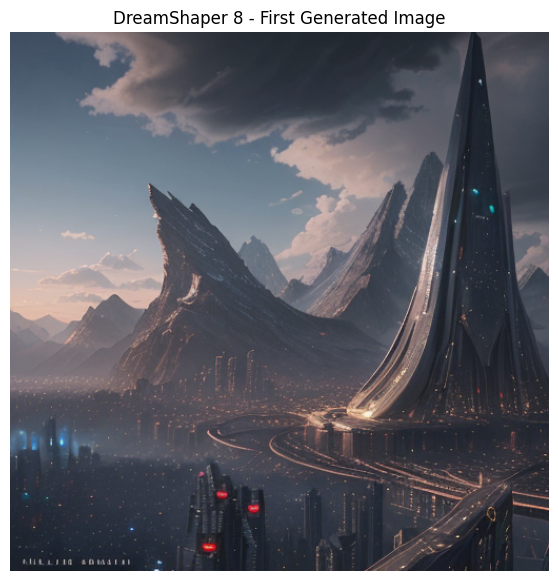

In [21]:

# ==========================================
# PHASE 3: FIRST IMAGE GENERATION
# ==========================================

import matplotlib.pyplot as plt
import time
import torch

PROMPT = (
    "A beautiful futuristic city surrounded by mountains, "
    "cinematic lighting, highly detailed architecture, "
    "realistic clouds, professional digital artwork"
)

SEED = 12345

generator = torch.Generator(
    device="cuda"
).manual_seed(SEED)

# Generation settings
HEIGHT = 512
WIDTH = 512
STEPS = 30
GUIDANCE = 7.5

# Reset peak memory statistics
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.inference_mode():
    result = pipe(
        prompt=PROMPT,
        height=HEIGHT,
        width=WIDTH,
        num_inference_steps=STEPS,
        guidance_scale=GUIDANCE,
        generator=generator
    )

torch.cuda.synchronize()

generation_time = time.perf_counter() - start_time

generated_image = result.images[0]

# Save image
image_path = IMAGE_DIR / "dreamshaper_first_image.png"
generated_image.save(image_path)

# Memory measurement
peak_allocated = torch.cuda.max_memory_allocated() / 1024**2
peak_reserved = torch.cuda.max_memory_reserved() / 1024**2

print("IMAGE GENERATED SUCCESSFULLY!")
print("Image path:", image_path)
print("Resolution:", generated_image.size)
print("Generation time:", round(generation_time, 2), "seconds")
print("Peak allocated memory:", round(peak_allocated, 2), "MB")
print("Peak reserved memory:", round(peak_reserved, 2), "MB")

# Display image
plt.figure(figsize=(7, 7))
plt.imshow(generated_image)
plt.axis("off")
plt.title("DreamShaper 8 - First Generated Image")
plt.show()


In [22]:

# ==================================================
# STEP 10: RECORD FP32 BASELINE
# ==================================================

import torch
import numpy as np
import pandas as pd
import cv2
import json
import time
from pathlib import Path

# Check required variables
assert "generated_image" in globals(), "Run Step 9 first!"
assert "generation_time" in globals(), "Generation time missing!"
assert "peak_allocated" in globals(), "GPU memory data missing!"
assert "peak_reserved" in globals(), "GPU memory data missing!"

# Calculate image quality metrics
image_array = np.array(generated_image.convert("RGB"))

gray_image = cv2.cvtColor(
    image_array,
    cv2.COLOR_RGB2GRAY
)

sharpness = cv2.Laplacian(
    gray_image,
    cv2.CV_64F
).var()

brightness = gray_image.mean()
contrast = gray_image.std()

# Create baseline record
baseline = {
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "run_id": "E1_FP32_BASELINE",
    "precision": "FP32",
    "scheduler": type(pipe.scheduler).__name__,
    "steps": 30,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
    "seed": 12345,
    "prompt_id": "P_FIRST",
    "latency_seconds": generation_time,
    "peak_allocated_mb": peak_allocated,
    "peak_reserved_mb": peak_reserved,
    "model_directory_size_mb": np.nan,
    "clip_similarity": np.nan,
    "sharpness_laplacian_var": sharpness,
    "brightness_mean": brightness,
    "contrast_std": contrast,
    "notes": "FP32 baseline"
}

# Initialize experiment results
experiment_rows = [baseline]

# Save baseline CSV
metrics_path = BASE_DIR / "member4_metrics.csv"

pd.DataFrame(experiment_rows).to_csv(
    metrics_path,
    index=False
)

print("FP32 BASELINE RECORDED SUCCESSFULLY!")
print("-----------------------------------")
print("Latency:", round(generation_time, 2), "seconds")
print("Peak allocated memory:", round(peak_allocated, 2), "MB")
print("Peak reserved memory:", round(peak_reserved, 2), "MB")
print("Sharpness:", round(sharpness, 2))
print("Brightness:", round(brightness, 2))
print("Contrast:", round(contrast, 2))
print("-----------------------------------")
print("CSV saved:", metrics_path)


FP32 BASELINE RECORDED SUCCESSFULLY!
-----------------------------------
Latency: 14.77 seconds
Peak allocated memory: 8669.61 MB
Peak reserved memory: 9642.0 MB
Sharpness: 463.18
Brightness: 86.14
Contrast: 41.59
-----------------------------------
CSV saved: /content/LiteGen_Member4/member4_metrics.csv


In [23]:

# ==================================================
# STEP 11: LOAD DREAMSHAPER 8 IN FP16
# ==================================================

import gc
import torch
import time

from diffusers import AutoPipelineForText2Image

# Delete FP32 model to free GPU memory
if "pipe" in globals():
    del pipe

gc.collect()
torch.cuda.empty_cache()

print("Loading DreamShaper 8 in FP16...")
print("Please wait...")

fp16_load_start = time.perf_counter()

pipe_fp16 = AutoPipelineForText2Image.from_pretrained(
    "Lykon/dreamshaper-8",
    torch_dtype=torch.float16
)

# Move model to GPU
pipe_fp16 = pipe_fp16.to("cuda")

fp16_load_time = time.perf_counter() - fp16_load_start

print("\nFP16 MODEL LOADED SUCCESSFULLY!")
print("-----------------------------------")
print("Model:", "Lykon/dreamshaper-8")
print("Pipeline:", type(pipe_fp16).__name__)
print("UNet precision:", pipe_fp16.unet.dtype)
print("Scheduler:", type(pipe_fp16.scheduler).__name__)
print("Load time:", round(fp16_load_time, 2), "seconds")
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**2, 2),
    "MB"
)


Loading DreamShaper 8 in FP16...
Please wait...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


FP16 MODEL LOADED SUCCESSFULLY!
-----------------------------------
Model: Lykon/dreamshaper-8
Pipeline: StableDiffusionPipeline
UNet precision: torch.float16
Scheduler: DEISMultistepScheduler
Load time: 18.68 seconds
GPU: Tesla T4
GPU memory allocated: 2646.44 MB


  0%|          | 0/30 [00:00<?, ?it/s]

FP16 IMAGE GENERATED SUCCESSFULLY!
-----------------------------------
Image: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16.png
Resolution: (512, 512)
Latency: 5.15 seconds
Peak allocated: 3257.71 MB
Peak reserved: 3830.0 MB


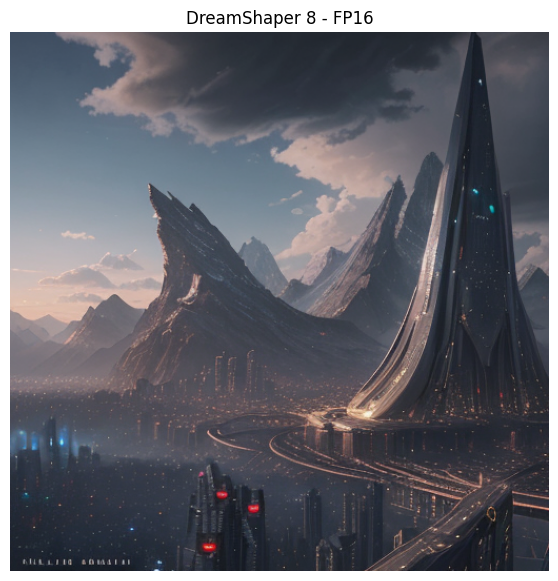

In [24]:

# ==================================================
# STEP 12: FP16 IMAGE GENERATION
# ==================================================

import torch
import time
import matplotlib.pyplot as plt

# Same prompt as FP32 baseline
PROMPT = (
    "A beautiful futuristic city surrounded by mountains, "
    "cinematic lighting, highly detailed architecture, "
    "realistic clouds, professional digital artwork"
)

SEED = 12345
HEIGHT = 512
WIDTH = 512
STEPS = 30
GUIDANCE = 7.5

# Set reproducible generator
generator_fp16 = torch.Generator(
    device="cuda"
).manual_seed(SEED)

# Reset memory statistics
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()

# Start timing
start_time = time.perf_counter()

# Generate image
with torch.inference_mode():

    result_fp16 = pipe_fp16(
        prompt=PROMPT,
        height=HEIGHT,
        width=WIDTH,
        num_inference_steps=STEPS,
        guidance_scale=GUIDANCE,
        generator=generator_fp16
    )

torch.cuda.synchronize()

# Stop timing
fp16_latency = time.perf_counter() - start_time

# IMPORTANT: Define fp16_image here
fp16_image = result_fp16.images[0]

# Measure GPU memory
fp16_allocated = (
    torch.cuda.max_memory_allocated() / 1024**2
)

fp16_reserved = (
    torch.cuda.max_memory_reserved() / 1024**2
)

# Save generated image
fp16_image_path = IMAGE_DIR / "dreamshaper_fp16.png"

fp16_image.save(fp16_image_path)

# Display results
print("FP16 IMAGE GENERATED SUCCESSFULLY!")
print("-----------------------------------")
print("Image:", fp16_image_path)
print("Resolution:", fp16_image.size)
print("Latency:", round(fp16_latency, 2), "seconds")
print("Peak allocated:", round(fp16_allocated, 2), "MB")
print("Peak reserved:", round(fp16_reserved, 2), "MB")

plt.figure(figsize=(7, 7))
plt.imshow(fp16_image)
plt.title("DreamShaper 8 - FP16")
plt.axis("off")
plt.show()


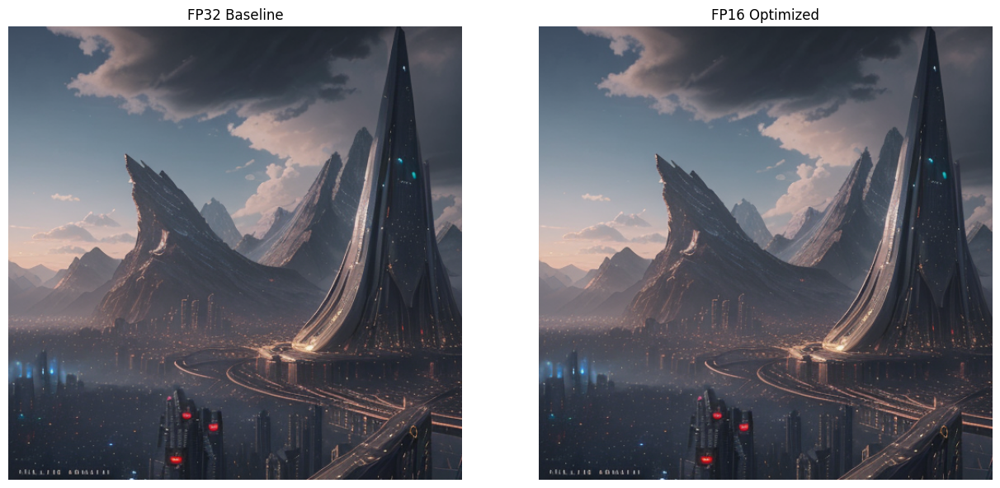

       FP32 VS FP16 PERFORMANCE

LATENCY
FP32: 14.77 seconds
FP16: 5.15 seconds
Improvement: 65.13 %

GPU PEAK ALLOCATED MEMORY
FP32: 8669.61 MB
FP16: 3257.71 MB
Improvement: 62.42 %

GPU PEAK RESERVED MEMORY
FP32: 9642.0 MB
FP16: 3830.0 MB

FP32 AND FP16 EXPERIMENTS SAVED!

           run_id precision  latency_seconds  peak_allocated_mb  peak_reserved_mb
E1_FP32_BASELINE      FP32        14.769806        8669.606934            9642.0
         E2_FP16      FP16         5.149909        3257.714355            3830.0

CSV location: /content/LiteGen_Member4/member4_metrics.csv
FP16 image: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16.png


In [25]:

# ==================================================
# STEP 13: FP32 VS FP16 COMPARISON
# ==================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cv2

# Verify all required variables
assert "generated_image" in globals()
assert "fp16_image" in globals()
assert "experiment_rows" in globals()

# ------------------------------------------
# 1. DISPLAY BOTH IMAGES
# ------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(generated_image)
axes[0].set_title("FP32 Baseline")
axes[0].axis("off")

axes[1].imshow(fp16_image)
axes[1].set_title("FP16 Optimized")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 2. CALCULATE PERFORMANCE IMPROVEMENTS
# ------------------------------------------

latency_improvement = (
    (generation_time - fp16_latency)
    / generation_time
) * 100

memory_improvement = (
    (peak_allocated - fp16_allocated)
    / peak_allocated
) * 100

print("=" * 50)
print("       FP32 VS FP16 PERFORMANCE")
print("=" * 50)

print("\nLATENCY")
print("FP32:", round(generation_time, 2), "seconds")
print("FP16:", round(fp16_latency, 2), "seconds")
print("Improvement:", round(latency_improvement, 2), "%")

print("\nGPU PEAK ALLOCATED MEMORY")
print("FP32:", round(peak_allocated, 2), "MB")
print("FP16:", round(fp16_allocated, 2), "MB")
print("Improvement:", round(memory_improvement, 2), "%")

print("\nGPU PEAK RESERVED MEMORY")
print("FP32:", round(peak_reserved, 2), "MB")
print("FP16:", round(fp16_reserved, 2), "MB")

# ------------------------------------------
# 3. CALCULATE FP16 IMAGE QUALITY METRICS
# ------------------------------------------

fp16_array = np.array(fp16_image.convert("RGB"))

fp16_gray = cv2.cvtColor(
    fp16_array,
    cv2.COLOR_RGB2GRAY
)

fp16_sharpness = cv2.Laplacian(
    fp16_gray,
    cv2.CV_64F
).var()

fp16_brightness = fp16_gray.mean()
fp16_contrast = fp16_gray.std()

# ------------------------------------------
# 4. CREATE FP16 EXPERIMENT RECORD
# ------------------------------------------

fp16_record = {
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "run_id": "E2_FP16",
    "precision": "FP16",
    "scheduler": type(pipe_fp16.scheduler).__name__,
    "steps": 30,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
    "seed": 12345,
    "prompt_id": "P_FIRST",
    "latency_seconds": fp16_latency,
    "peak_allocated_mb": fp16_allocated,
    "peak_reserved_mb": fp16_reserved,
    "model_directory_size_mb": np.nan,
    "clip_similarity": np.nan,
    "sharpness_laplacian_var": fp16_sharpness,
    "brightness_mean": fp16_brightness,
    "contrast_std": fp16_contrast,
    "notes": "FP16 optimization"
}

# ------------------------------------------
# 5. APPEND TO EXPERIMENT RESULTS
# ------------------------------------------

# Avoid duplicate records if this cell is rerun
experiment_rows = [
    row for row in experiment_rows
    if row["run_id"] != "E2_FP16"
]

experiment_rows.append(fp16_record)

# Save updated CSV
metrics_path = BASE_DIR / "member4_metrics.csv"

df = pd.DataFrame(experiment_rows)

df.to_csv(metrics_path, index=False)

print("\n" + "=" * 50)
print("FP32 AND FP16 EXPERIMENTS SAVED!")
print("=" * 50)

print("\n", df[[
    "run_id",
    "precision",
    "latency_seconds",
    "peak_allocated_mb",
    "peak_reserved_mb"
]].to_string(index=False))

print("\nCSV location:", metrics_path)
print("FP16 image:", fp16_image_path)


In [26]:

# ==================================================
# STEP 14: INFERENCE STEP OPTIMIZATION
# DreamShaper 8 - FP16
# ==================================================

import torch
import time
import gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# Experiment configurations
STEP_VALUES = [30, 20, 10, 5]

# Same prompt and seed for fair comparison
PROMPT = (
    "A beautiful futuristic city surrounded by mountains, "
    "cinematic lighting, highly detailed architecture, "
    "realistic clouds, professional digital artwork"
)

SEED = 12345
HEIGHT = 512
WIDTH = 512
GUIDANCE = 7.5

step_results = []

print("=" * 55)
print("DREAMSHAPER 8 - INFERENCE STEP EXPERIMENT")
print("=" * 55)

for steps in STEP_VALUES:

    print(f"\nRunning experiment: {steps} steps")

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(SEED)

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():

        result = pipe_fp16(
            prompt=PROMPT,
            height=HEIGHT,
            width=WIDTH,
            num_inference_steps=steps,
            guidance_scale=GUIDANCE,
            generator=generator
        )

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    image = result.images[0]

    # GPU memory
    allocated = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    reserved = (
        torch.cuda.max_memory_reserved() / 1024**2
    )

    # Image quality metrics
    image_array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2GRAY
    )

    sharpness = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    brightness = gray.mean()
    contrast = gray.std()

    # Save image
    image_path = IMAGE_DIR / f"dreamshaper_fp16_{steps}_steps.png"

    image.save(image_path)

    # Store experiment result
    record = {
        "member": 4,
        "model_id": MODEL_ID,
        "run_id": f"E3_FP16_{steps}_STEPS",
        "precision": "FP16",
        "scheduler": type(pipe_fp16.scheduler).__name__,
        "steps": steps,
        "guidance_scale": GUIDANCE,
        "height": HEIGHT,
        "width": WIDTH,
        "seed": SEED,
        "prompt_id": "P_FIRST",
        "latency_seconds": elapsed,
        "peak_allocated_mb": allocated,
        "peak_reserved_mb": reserved,
        "model_directory_size_mb": np.nan,
        "clip_similarity": np.nan,
        "sharpness_laplacian_var": sharpness,
        "brightness_mean": brightness,
        "contrast_std": contrast,
        "notes": "FP16 inference step experiment"
    }

    step_results.append(record)

    print("Completed!")
    print("Time:", round(elapsed, 2), "seconds")
    print("Peak memory:", round(allocated, 2), "MB")
    print("Sharpness:", round(sharpness, 2))
    print("Image saved:", image_path)

# Save experiment results
step_df = pd.DataFrame(step_results)

# Remove old copies if this cell is rerun
experiment_rows = [
    row for row in experiment_rows
    if not row["run_id"].startswith("E3_FP16_")
]

experiment_rows.extend(step_results)

metrics_path = BASE_DIR / "member4_metrics.csv"

pd.DataFrame(experiment_rows).to_csv(
    metrics_path,
    index=False
)

print("\n" + "=" * 55)
print("ALL STEP EXPERIMENTS COMPLETED!")
print("=" * 55)

print(step_df[[
    "run_id",
    "steps",
    "latency_seconds",
    "peak_allocated_mb",
    "sharpness_laplacian_var"
]].to_string(index=False))

print("\nCSV updated:", metrics_path)


DREAMSHAPER 8 - INFERENCE STEP EXPERIMENT

Running experiment: 30 steps


  0%|          | 0/30 [00:00<?, ?it/s]

Completed!
Time: 4.7 seconds
Peak memory: 3257.71 MB
Sharpness: 463.61
Image saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16_30_steps.png

Running experiment: 20 steps


  0%|          | 0/20 [00:00<?, ?it/s]

Completed!
Time: 3.22 seconds
Peak memory: 3257.71 MB
Sharpness: 489.72
Image saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16_20_steps.png

Running experiment: 10 steps


  0%|          | 0/10 [00:00<?, ?it/s]

Completed!
Time: 1.73 seconds
Peak memory: 3257.71 MB
Sharpness: 363.85
Image saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16_10_steps.png

Running experiment: 5 steps


  0%|          | 0/5 [00:00<?, ?it/s]

Completed!
Time: 0.99 seconds
Peak memory: 3257.71 MB
Sharpness: 470.12
Image saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_fp16_5_steps.png

ALL STEP EXPERIMENTS COMPLETED!
          run_id  steps  latency_seconds  peak_allocated_mb  sharpness_laplacian_var
E3_FP16_30_STEPS     30         4.702183        3257.714355               463.613224
E3_FP16_20_STEPS     20         3.219280        3257.714355               489.716892
E3_FP16_10_STEPS     10         1.733776        3257.714355               363.849218
 E3_FP16_5_STEPS      5         0.991573        3257.714355               470.124170

CSV updated: /content/LiteGen_Member4/member4_metrics.csv


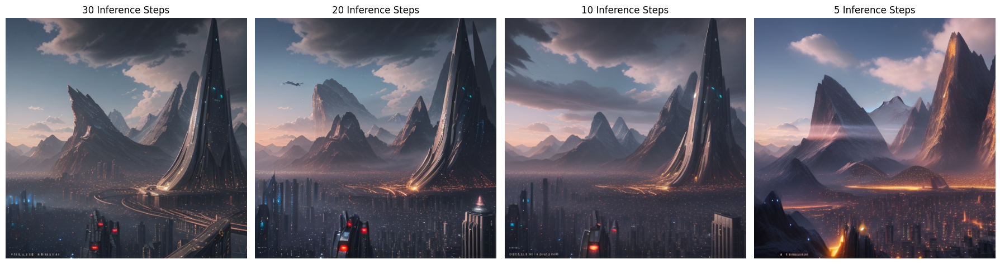

In [27]:

# ==================================================
# STEP 14.2: VISUAL IMAGE COMPARISON
# ==================================================

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, steps in enumerate([30, 20, 10, 5]):

    image_path = IMAGE_DIR / f"dreamshaper_fp16_{steps}_steps.png"

    img = Image.open(image_path)

    axes[i].imshow(img)
    axes[i].set_title(f"{steps} Inference Steps")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


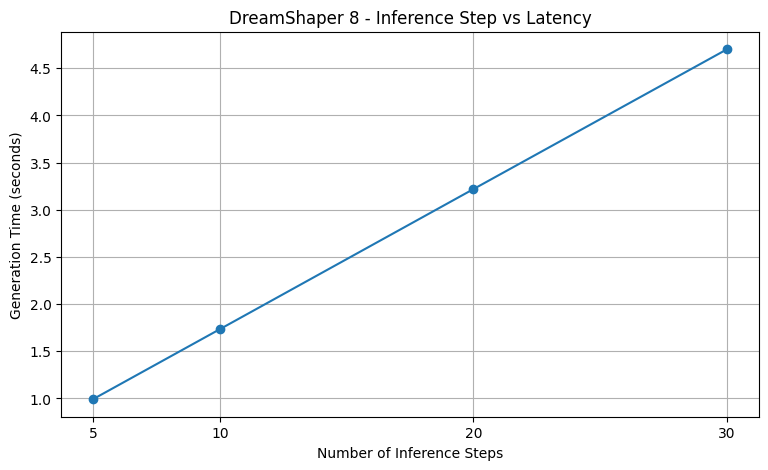


LATENCY RESULTS
30 steps: 4.70 seconds
20 steps: 3.22 seconds
10 steps: 1.73 seconds
5 steps: 0.99 seconds


In [28]:

# ==================================================
# STEP 14.3: LATENCY COMPARISON GRAPH
# ==================================================

import matplotlib.pyplot as plt

plot_df = pd.DataFrame(step_results)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_df["steps"],
    plot_df["latency_seconds"],
    marker="o"
)

plt.xlabel("Number of Inference Steps")
plt.ylabel("Generation Time (seconds)")
plt.title("DreamShaper 8 - Inference Step vs Latency")

plt.xticks([5, 10, 20, 30])
plt.grid(True)

plt.show()

print("\nLATENCY RESULTS")

for _, row in plot_df.sort_values("steps", ascending=False).iterrows():

    print(
        f'{row["steps"]} steps: '
        f'{row["latency_seconds"]:.2f} seconds'
    )


In [29]:

# ==================================================
# STEP 15.1: RESOLUTION OPTIMIZATION
# DREAMSHAPER 8 - FP16
# ==================================================

import torch
import time
import gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

RESOLUTIONS = [
    (384, 384),
    (512, 512)
]

RESOLUTION_STEPS = 20

resolution_results = []
resolution_images = {}

print("=" * 55)
print("DREAMSHAPER 8 - RESOLUTION EXPERIMENT")
print("=" * 55)

for height, width in RESOLUTIONS:

    print(f"\nGenerating {height}x{width} image...")

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(12345)

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():

        result = pipe_fp16(
            prompt=PROMPT,
            height=height,
            width=width,
            num_inference_steps=RESOLUTION_STEPS,
            guidance_scale=7.5,
            generator=generator
        )

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    image = result.images[0]
    resolution_images[height] = image

    # GPU memory measurements
    allocated = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    reserved = (
        torch.cuda.max_memory_reserved() / 1024**2
    )

    # Image quality metrics
    image_array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2GRAY
    )

    sharpness = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    brightness = gray.mean()
    contrast = gray.std()

    # Save image
    image_path = IMAGE_DIR / (
        f"dreamshaper_{height}x{width}.png"
    )

    image.save(image_path)

    record = {
        "member": 4,
        "model_id": MODEL_ID,
        "run_id": f"E4_FP16_{height}x{width}",
        "precision": "FP16",
        "scheduler": type(pipe_fp16.scheduler).__name__,
        "steps": RESOLUTION_STEPS,
        "guidance_scale": 7.5,
        "height": height,
        "width": width,
        "seed": 12345,
        "prompt_id": "P_FIRST",
        "latency_seconds": elapsed,
        "peak_allocated_mb": allocated,
        "peak_reserved_mb": reserved,
        "model_directory_size_mb": np.nan,
        "clip_similarity": np.nan,
        "sharpness_laplacian_var": sharpness,
        "brightness_mean": brightness,
        "contrast_std": contrast,
        "notes": "FP16 resolution experiment"
    }

    resolution_results.append(record)

    print("Completed!")
    print("Time:", round(elapsed, 2), "seconds")
    print("Peak memory:", round(allocated, 2), "MB")
    print("Sharpness:", round(sharpness, 2))
    print("Saved:", image_path)

print("\nRESOLUTION EXPERIMENT COMPLETED!")


DREAMSHAPER 8 - RESOLUTION EXPERIMENT

Generating 384x384 image...


  0%|          | 0/20 [00:00<?, ?it/s]

Completed!
Time: 2.11 seconds
Peak memory: 2990.95 MB
Sharpness: 801.22
Saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_384x384.png

Generating 512x512 image...


  0%|          | 0/20 [00:00<?, ?it/s]

Completed!
Time: 3.24 seconds
Peak memory: 3257.71 MB
Sharpness: 489.72
Saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_512x512.png

RESOLUTION EXPERIMENT COMPLETED!


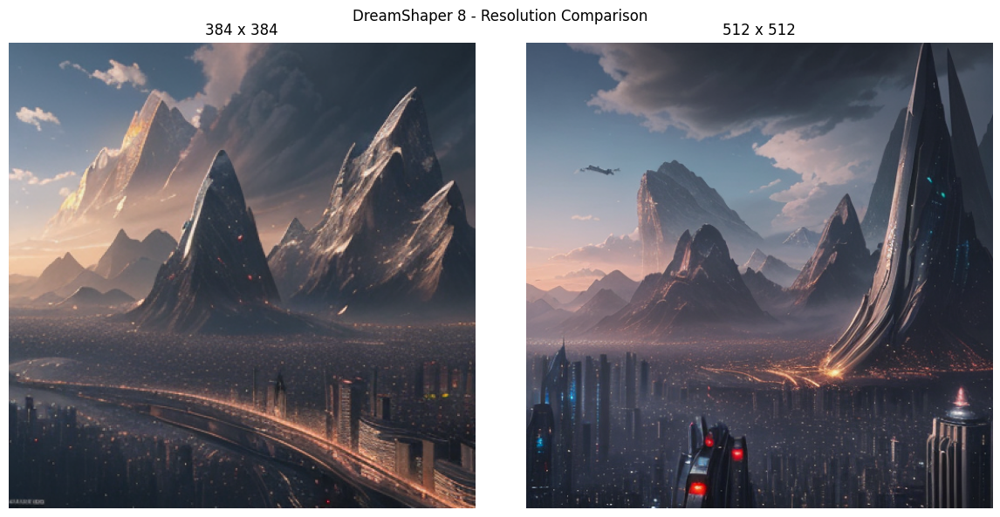

In [30]:

# ==================================================
# STEP 15.2: VISUAL COMPARISON
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, resolution in zip(axes, [384, 512]):

    ax.imshow(resolution_images[resolution])

    ax.set_title(
        f"{resolution} x {resolution}"
    )

    ax.axis("off")

plt.suptitle("DreamShaper 8 - Resolution Comparison")
plt.tight_layout()
plt.show()


In [31]:

# ==================================================
# STEP 15.3: RESOLUTION PERFORMANCE ANALYSIS
# ==================================================

resolution_df = pd.DataFrame(resolution_results)

print("=" * 55)
print("RESOLUTION PERFORMANCE RESULTS")
print("=" * 55)

print(
    resolution_df[[
        "height",
        "width",
        "latency_seconds",
        "peak_allocated_mb",
        "peak_reserved_mb",
        "sharpness_laplacian_var"
    ]].to_string(index=False)
)

# Calculate improvement of 384 compared with 512
row_384 = resolution_df[
    resolution_df["height"] == 384
].iloc[0]

row_512 = resolution_df[
    resolution_df["height"] == 512
].iloc[0]

time_change = (
    (row_512["latency_seconds"] - row_384["latency_seconds"])
    / row_512["latency_seconds"]
) * 100

memory_change = (
    (row_512["peak_allocated_mb"] - row_384["peak_allocated_mb"])
    / row_512["peak_allocated_mb"]
) * 100

print("\n384x384 relative improvement over 512x512")

print("Latency:", round(time_change, 2), "%")
print("Peak allocated memory:", round(memory_change, 2), "%")


RESOLUTION PERFORMANCE RESULTS
 height  width  latency_seconds  peak_allocated_mb  peak_reserved_mb  sharpness_laplacian_var
    384    384         2.114096        2990.952148            3336.0               801.216235
    512    512         3.238595        3257.714355            3830.0               489.716892

384x384 relative improvement over 512x512
Latency: 34.72 %
Peak allocated memory: 8.19 %


In [32]:

# ==================================================
# STEP 15.4: SAVE RESOLUTION RESULTS
# ==================================================

# Remove old resolution experiment records if rerunning
experiment_rows = [
    row for row in experiment_rows
    if not row["run_id"].startswith("E4_FP16_")
]

experiment_rows.extend(resolution_results)

metrics_path = BASE_DIR / "member4_metrics.csv"

final_df = pd.DataFrame(experiment_rows)

final_df.to_csv(
    metrics_path,
    index=False
)

print("RESOLUTION RESULTS SAVED!")
print("CSV:", metrics_path)
print("Total experiment records:", len(final_df))


RESOLUTION RESULTS SAVED!
CSV: /content/LiteGen_Member4/member4_metrics.csv
Total experiment records: 8


In [33]:

# ==================================================
# STEP 16.1: IMPORT ALTERNATIVE SCHEDULER
# ==================================================

from diffusers import DPMSolverMultistepScheduler

print("Original scheduler:")
print(type(pipe_fp16.scheduler).__name__)

# Save original scheduler configuration
original_scheduler = pipe_fp16.scheduler

print("\nAlternative scheduler:")
print("DPMSolverMultistepScheduler")

print("\nScheduler import successful!")


Original scheduler:
DEISMultistepScheduler

Alternative scheduler:
DPMSolverMultistepScheduler

Scheduler import successful!


In [34]:

# ==================================================
# STEP 16.2: ORIGINAL SCHEDULER BENCHMARK
# ==================================================

import torch
import time
import gc
import numpy as np
import cv2

SCHEDULER_STEPS = 20
SCHEDULER_HEIGHT = 512
SCHEDULER_WIDTH = 512

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

generator = torch.Generator(
    device="cuda"
).manual_seed(12345)

torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():

    original_result = pipe_fp16(
        prompt=PROMPT,
        height=SCHEDULER_HEIGHT,
        width=SCHEDULER_WIDTH,
        num_inference_steps=SCHEDULER_STEPS,
        guidance_scale=7.5,
        generator=generator
    )

torch.cuda.synchronize()

original_latency = time.perf_counter() - start

original_image = original_result.images[0]

original_allocated = (
    torch.cuda.max_memory_allocated() / 1024**2
)

original_reserved = (
    torch.cuda.max_memory_reserved() / 1024**2
)

original_image.save(
    IMAGE_DIR / "scheduler_original.png"
)

print("ORIGINAL SCHEDULER COMPLETED!")
print("Scheduler:", type(original_scheduler).__name__)
print("Latency:", round(original_latency, 2), "seconds")
print("Peak allocated:", round(original_allocated, 2), "MB")
print("Peak reserved:", round(original_reserved, 2), "MB")


  0%|          | 0/20 [00:00<?, ?it/s]

ORIGINAL SCHEDULER COMPLETED!
Scheduler: DEISMultistepScheduler
Latency: 3.32 seconds
Peak allocated: 3257.71 MB
Peak reserved: 3830.0 MB


In [37]:

# ==================================================
# STEP 16.3: FIXED DPMSOLVER SCHEDULER SETUP
# ==================================================

from diffusers import DPMSolverMultistepScheduler

# Preserve original scheduler configuration
original_scheduler = pipe_fp16.scheduler

print("Original scheduler:", type(original_scheduler).__name__)

# Create alternative scheduler
dpm_scheduler = DPMSolverMultistepScheduler.from_config(
    original_scheduler.config,
    algorithm_type="dpmsolver++",
    solver_order=2
)

# Apply alternative scheduler
pipe_fp16.scheduler = dpm_scheduler

print("\nAlternative scheduler configured!")
print("Current scheduler:", type(pipe_fp16.scheduler).__name__)
print("Model precision:", pipe_fp16.unet.dtype)


Original scheduler: DEISMultistepScheduler

Alternative scheduler configured!
Current scheduler: DPMSolverMultistepScheduler
Model precision: torch.float16


In [38]:

# ==================================================
# STEP 16.4: DPMSOLVER IMAGE GENERATION
# ==================================================

import torch
import time
import gc

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

generator = torch.Generator(
    device="cuda"
).manual_seed(12345)

torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():

    dpm_result = pipe_fp16(
        prompt=PROMPT,
        height=512,
        width=512,
        num_inference_steps=20,
        guidance_scale=7.5,
        generator=generator
    )

torch.cuda.synchronize()

dpm_latency = time.perf_counter() - start

dpm_image = dpm_result.images[0]

dpm_allocated = (
    torch.cuda.max_memory_allocated() / 1024**2
)

dpm_reserved = (
    torch.cuda.max_memory_reserved() / 1024**2
)

dpm_image.save(
    IMAGE_DIR / "scheduler_dpm.png"
)

print("DPMSOLVER GENERATION COMPLETED!")
print("Latency:", round(dpm_latency, 2), "seconds")
print("Peak allocated:", round(dpm_allocated, 2), "MB")
print("Peak reserved:", round(dpm_reserved, 2), "MB")


  0%|          | 0/20 [00:00<?, ?it/s]

DPMSOLVER GENERATION COMPLETED!
Latency: 3.24 seconds
Peak allocated: 3257.78 MB
Peak reserved: 3830.0 MB


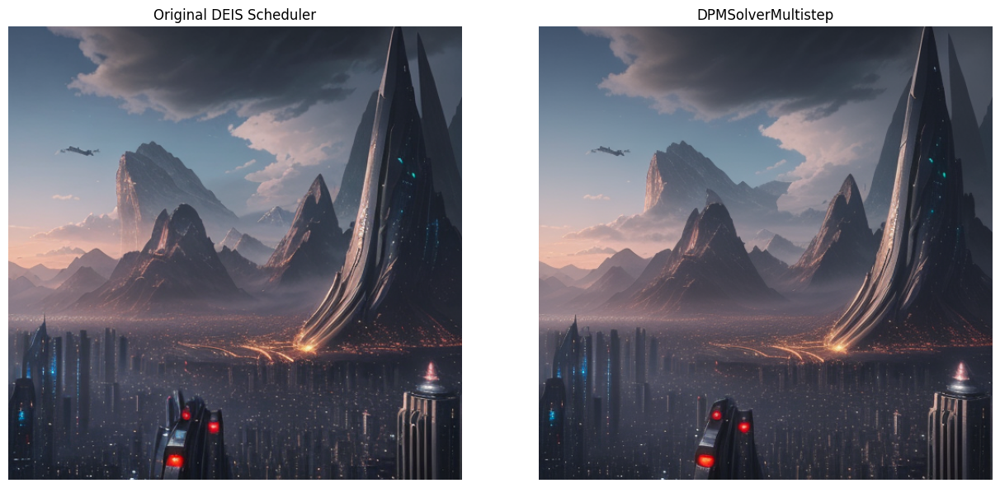

Original scheduler: 3.32 seconds
DPM scheduler: 3.24 seconds
Latency improvement: 2.39 %


In [39]:

# ==================================================
# STEP 16.5: VISUAL COMPARISON
# ==================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(original_image)
axes[0].set_title("Original DEIS Scheduler")
axes[0].axis("off")

axes[1].imshow(dpm_image)
axes[1].set_title("DPMSolverMultistep")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original scheduler:", round(original_latency, 2), "seconds")
print("DPM scheduler:", round(dpm_latency, 2), "seconds")

improvement = (
    (original_latency - dpm_latency) / original_latency
) * 100

print("Latency improvement:", round(improvement, 2), "%")


In [40]:

# ==================================================
# STEP 16.6: SAVE SCHEDULER EXPERIMENT RESULTS
# ==================================================

import numpy as np
import pandas as pd
import cv2
import torch

# ------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------

required_variables = [
    "original_image",
    "dpm_image",
    "original_latency",
    "dpm_latency",
    "original_allocated",
    "original_reserved",
    "dpm_allocated",
    "dpm_reserved",
    "original_scheduler",
    "pipe_fp16",
    "experiment_rows"
]

for variable in required_variables:
    assert variable in globals(), (
        f"Missing variable: {variable}. "
        "Run the previous scheduler steps first."
    )

# ------------------------------------------
# 2. IMAGE QUALITY METRICS FUNCTION
# ------------------------------------------

def calculate_image_metrics(image):

    array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        array,
        cv2.COLOR_RGB2GRAY
    )

    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    brightness = gray.mean()
    contrast = gray.std()

    return {
        "sharpness_laplacian_var": float(sharpness),
        "brightness_mean": float(brightness),
        "contrast_std": float(contrast)
    }


# Calculate metrics
original_metrics = calculate_image_metrics(
    original_image
)

dpm_metrics = calculate_image_metrics(
    dpm_image
)

# ------------------------------------------
# 3. CREATE EXPERIMENT RECORDS
# ------------------------------------------

scheduler_records = []

scheduler_data = [
    {
        "run_id": "E5_ORIGINAL_SCHEDULER",
        "scheduler": type(original_scheduler).__name__,
        "latency": original_latency,
        "allocated": original_allocated,
        "reserved": original_reserved,
        "metrics": original_metrics
    },
    {
        "run_id": "E5_DPMSOLVER",
        "scheduler": type(pipe_fp16.scheduler).__name__,
        "latency": dpm_latency,
        "allocated": dpm_allocated,
        "reserved": dpm_reserved,
        "metrics": dpm_metrics
    }
]

for item in scheduler_data:

    record = {
        "member": 4,
        "model_id": MODEL_ID,
        "run_id": item["run_id"],
        "precision": "FP16",
        "scheduler": item["scheduler"],
        "steps": 20,
        "guidance_scale": 7.5,
        "height": 512,
        "width": 512,
        "seed": 12345,
        "prompt_id": "P_FIRST",
        "latency_seconds": item["latency"],
        "peak_allocated_mb": item["allocated"],
        "peak_reserved_mb": item["reserved"],
        "model_directory_size_mb": np.nan,
        "clip_similarity": np.nan,
        "sharpness_laplacian_var":
            item["metrics"]["sharpness_laplacian_var"],
        "brightness_mean":
            item["metrics"]["brightness_mean"],
        "contrast_std":
            item["metrics"]["contrast_std"],
        "notes": "FP16 scheduler comparison"
    }

    scheduler_records.append(record)

# ------------------------------------------
# 4. UPDATE EXPERIMENT RESULTS
# ------------------------------------------

# Remove previous scheduler records if rerunning
experiment_rows = [
    row for row in experiment_rows
    if not row["run_id"].startswith("E5_")
]

experiment_rows.extend(scheduler_records)

# ------------------------------------------
# 5. SAVE CSV
# ------------------------------------------

metrics_path = BASE_DIR / "member4_metrics.csv"

scheduler_df = pd.DataFrame(experiment_rows)

scheduler_df.to_csv(
    metrics_path,
    index=False
)

# ------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------

print("=" * 60)
print("SCHEDULER EXPERIMENTS SAVED SUCCESSFULLY!")
print("=" * 60)

print("\nSCHEDULER COMPARISON")

print(
    pd.DataFrame(scheduler_records)[[
        "run_id",
        "scheduler",
        "latency_seconds",
        "peak_allocated_mb",
        "peak_reserved_mb",
        "sharpness_laplacian_var",
        "brightness_mean",
        "contrast_std"
    ]].to_string(index=False)
)

print("\nTotal experiment records:", len(scheduler_df))
print("CSV saved at:", metrics_path)

print("\nSTEP 16 COMPLETED!")


SCHEDULER EXPERIMENTS SAVED SUCCESSFULLY!

SCHEDULER COMPARISON
               run_id                   scheduler  latency_seconds  peak_allocated_mb  peak_reserved_mb  sharpness_laplacian_var  brightness_mean  contrast_std
E5_ORIGINAL_SCHEDULER      DEISMultistepScheduler         3.323250        3257.714355            3830.0               489.716892        85.355831     43.827335
         E5_DPMSOLVER DPMSolverMultistepScheduler         3.243791        3257.777344            3830.0               471.175813        85.918262     43.399049

Total experiment records: 10
CSV saved at: /content/LiteGen_Member4/member4_metrics.csv

STEP 16 COMPLETED!


In [41]:

# ==================================================
# STEP 17.1: COMBINED OPTIMIZATION CONFIGURATION
# ==================================================

import torch
import gc
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# Combined configuration
COMBINED_PRECISION = torch.float16
COMBINED_STEPS = 20
COMBINED_HEIGHT = 512
COMBINED_WIDTH = 512
COMBINED_GUIDANCE = 7.5
COMBINED_SEED = 12345

# Configure DPMSolver scheduler
from diffusers import DPMSolverMultistepScheduler

pipe_fp16.scheduler = DPMSolverMultistepScheduler.from_config(
    original_scheduler.config,
    algorithm_type="dpmsolver++",
    solver_order=2
)

print("=" * 55)
print("COMBINED OPTIMIZATION CONFIGURATION")
print("=" * 55)

print("Model:", MODEL_ID)
print("Precision:", pipe_fp16.unet.dtype)
print("Scheduler:", type(pipe_fp16.scheduler).__name__)
print("Inference steps:", COMBINED_STEPS)
print("Resolution:", COMBINED_HEIGHT, "x", COMBINED_WIDTH)
print("Guidance scale:", COMBINED_GUIDANCE)
print("Seed:", COMBINED_SEED)

print("\nConfiguration ready!")


COMBINED OPTIMIZATION CONFIGURATION
Model: Lykon/dreamshaper-8
Precision: torch.float16
Scheduler: DPMSolverMultistepScheduler
Inference steps: 20
Resolution: 512 x 512
Guidance scale: 7.5
Seed: 12345

Configuration ready!


  0%|          | 0/20 [00:00<?, ?it/s]

COMBINED GENERATION SUCCESSFUL!
Generation time: 4.08 seconds
Peak allocated memory: 3257.84 MB
Peak reserved memory: 3830.0 MB
Image resolution: (512, 512)
Image saved: /content/LiteGen_Member4/outputs/generated_images/dreamshaper_combined_optimized.png


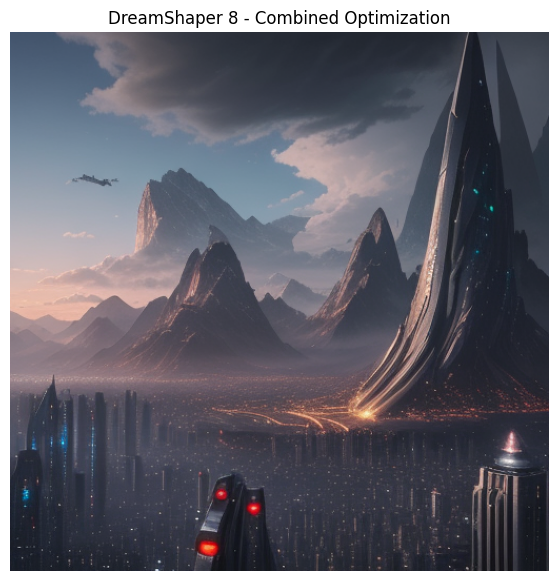

In [42]:

# ==================================================
# STEP 17.2: COMBINED OPTIMIZED GENERATION
# ==================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

combined_generator = torch.Generator(
    device="cuda"
).manual_seed(COMBINED_SEED)

torch.cuda.synchronize()

combined_start = time.perf_counter()

with torch.inference_mode():

    combined_result = pipe_fp16(
        prompt=PROMPT,
        height=COMBINED_HEIGHT,
        width=COMBINED_WIDTH,
        num_inference_steps=COMBINED_STEPS,
        guidance_scale=COMBINED_GUIDANCE,
        generator=combined_generator
    )

torch.cuda.synchronize()

combined_latency = time.perf_counter() - combined_start

# Extract image
combined_image = combined_result.images[0]

# GPU memory
combined_allocated = (
    torch.cuda.max_memory_allocated() / 1024**2
)

combined_reserved = (
    torch.cuda.max_memory_reserved() / 1024**2
)

# Save image
combined_image_path = (
    IMAGE_DIR / "dreamshaper_combined_optimized.png"
)

combined_image.save(combined_image_path)

print("=" * 55)
print("COMBINED GENERATION SUCCESSFUL!")
print("=" * 55)

print("Generation time:", round(combined_latency, 2), "seconds")
print("Peak allocated memory:", round(combined_allocated, 2), "MB")
print("Peak reserved memory:", round(combined_reserved, 2), "MB")
print("Image resolution:", combined_image.size)
print("Image saved:", combined_image_path)

plt.figure(figsize=(7, 7))
plt.imshow(combined_image)
plt.title("DreamShaper 8 - Combined Optimization")
plt.axis("off")
plt.show()


In [43]:

# ==================================================
# STEP 17.3: COMBINED IMAGE QUALITY METRICS
# ==================================================

combined_array = np.array(
    combined_image.convert("RGB")
)

combined_gray = cv2.cvtColor(
    combined_array,
    cv2.COLOR_RGB2GRAY
)

combined_sharpness = cv2.Laplacian(
    combined_gray,
    cv2.CV_64F
).var()

combined_brightness = combined_gray.mean()
combined_contrast = combined_gray.std()

print("COMBINED IMAGE QUALITY METRICS")
print("-----------------------------------")

print(
    "Laplacian Sharpness:",
    round(combined_sharpness, 2)
)

print(
    "Brightness Mean:",
    round(combined_brightness, 2)
)

print(
    "Contrast Standard Deviation:",
    round(combined_contrast, 2)
)


COMBINED IMAGE QUALITY METRICS
-----------------------------------
Laplacian Sharpness: 471.18
Brightness Mean: 85.92
Contrast Standard Deviation: 43.4


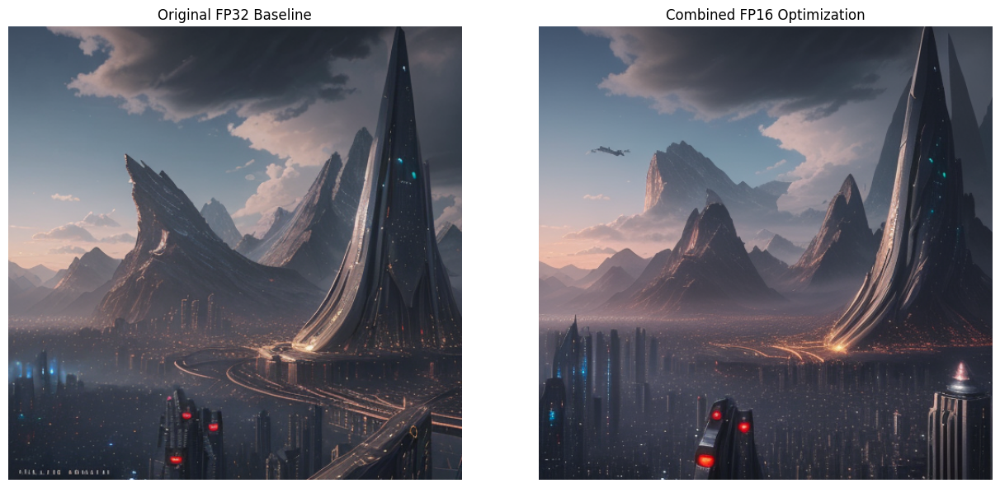

BASELINE VS COMBINED OPTIMIZATION

LATENCY
Baseline: 14.77 seconds
Combined: 4.08 seconds
Improvement: 72.38 %

GPU MEMORY
Baseline: 8669.61 MB
Combined: 3257.84 MB
Improvement: 62.42 %


In [44]:

# ==================================================
# STEP 17.4: BASELINE VS COMBINED COMPARISON
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(generated_image)
axes[0].set_title("Original FP32 Baseline")
axes[0].axis("off")

axes[1].imshow(combined_image)
axes[1].set_title("Combined FP16 Optimization")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Latency improvement
latency_improvement = (
    (generation_time - combined_latency)
    / generation_time
) * 100

# Memory improvement
memory_improvement = (
    (peak_allocated - combined_allocated)
    / peak_allocated
) * 100

print("=" * 55)
print("BASELINE VS COMBINED OPTIMIZATION")
print("=" * 55)

print("\nLATENCY")
print("Baseline:", round(generation_time, 2), "seconds")
print("Combined:", round(combined_latency, 2), "seconds")
print("Improvement:", round(latency_improvement, 2), "%")

print("\nGPU MEMORY")
print("Baseline:", round(peak_allocated, 2), "MB")
print("Combined:", round(combined_allocated, 2), "MB")
print("Improvement:", round(memory_improvement, 2), "%")


In [45]:

# ==================================================
# STEP 17.5: SAVE COMBINED OPTIMIZATION RESULTS
# ==================================================

combined_record = {
    "member": 4,
    "model_id": MODEL_ID,
    "run_id": "E6_COMBINED_OPTIMIZATION",
    "precision": "FP16",
    "scheduler": type(pipe_fp16.scheduler).__name__,
    "steps": COMBINED_STEPS,
    "guidance_scale": COMBINED_GUIDANCE,
    "height": COMBINED_HEIGHT,
    "width": COMBINED_WIDTH,
    "seed": COMBINED_SEED,
    "prompt_id": "P_FIRST",
    "latency_seconds": combined_latency,
    "peak_allocated_mb": combined_allocated,
    "peak_reserved_mb": combined_reserved,
    "model_directory_size_mb": np.nan,
    "clip_similarity": np.nan,
    "sharpness_laplacian_var": combined_sharpness,
    "brightness_mean": combined_brightness,
    "contrast_std": combined_contrast,
    "notes": "Combined FP16, DPMSolver, 20 steps, 512 resolution"
}

# Prevent duplicate records if rerunning
experiment_rows = [
    row for row in experiment_rows
    if row["run_id"] != "E6_COMBINED_OPTIMIZATION"
]

experiment_rows.append(combined_record)

# Save complete CSV
metrics_path = BASE_DIR / "member4_metrics.csv"

combined_df = pd.DataFrame(experiment_rows)

combined_df.to_csv(
    metrics_path,
    index=False
)

print("=" * 55)
print("COMBINED EXPERIMENT SAVED!")
print("=" * 55)

print("\n", combined_df[[
    "run_id",
    "precision",
    "scheduler",
    "steps",
    "height",
    "latency_seconds",
    "peak_allocated_mb"
]].tail().to_string(index=False))

print("\nTotal experiment records:", len(combined_df))
print("CSV location:", metrics_path)


COMBINED EXPERIMENT SAVED!

                   run_id precision                   scheduler  steps  height  latency_seconds  peak_allocated_mb
         E4_FP16_384x384      FP16      DEISMultistepScheduler     20     384         2.114096        2990.952148
         E4_FP16_512x512      FP16      DEISMultistepScheduler     20     512         3.238595        3257.714355
   E5_ORIGINAL_SCHEDULER      FP16      DEISMultistepScheduler     20     512         3.323250        3257.714355
            E5_DPMSOLVER      FP16 DPMSolverMultistepScheduler     20     512         3.243791        3257.777344
E6_COMBINED_OPTIMIZATION      FP16 DPMSolverMultistepScheduler     20     512         4.079148        3257.840332

Total experiment records: 11
CSV location: /content/LiteGen_Member4/member4_metrics.csv


In [46]:

# ==================================================
# STEP 18.1: DREAMSHAPER 8 MODEL SIZE MEASUREMENT
# ==================================================

import os
import json
from pathlib import Path
from huggingface_hub import snapshot_download

MODEL_ID = "Lykon/dreamshaper-8"

print("Locating downloaded DreamShaper 8 checkpoint...")

model_directory = Path(
    snapshot_download(repo_id=MODEL_ID)
)

# Count unique physical files to avoid counting
# the same cached file more than once.
unique_files = set()
total_bytes = 0

for file_path in model_directory.rglob("*"):

    if file_path.is_file():

        resolved_path = file_path.resolve()

        if resolved_path not in unique_files:
            unique_files.add(resolved_path)
            total_bytes += resolved_path.stat().st_size

model_size_mb = total_bytes / (1024 ** 2)
model_size_gb = total_bytes / (1024 ** 3)

print("\nMODEL SIZE MEASUREMENT COMPLETED!")
print("-----------------------------------")
print("Model:", MODEL_ID)
print("Model directory:", model_directory)
print("Unique files:", len(unique_files))
print("Model size:", round(model_size_mb, 2), "MiB")
print("Model size:", round(model_size_gb, 3), "GiB")

# Save model size information
model_metadata = {
    "model_id": MODEL_ID,
    "model_directory": str(model_directory),
    "unique_file_count": len(unique_files),
    "model_size_mb": round(model_size_mb, 2),
    "model_size_gb": round(model_size_gb, 3)
}

with open(BASE_DIR / "model_metadata.json", "w") as f:
    json.dump(model_metadata, f, indent=4)

print("\nMetadata saved:", BASE_DIR / "model_metadata.json")


Locating downloaded DreamShaper 8 checkpoint...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 22 files:   0%|          | 0/22 [00:00<?, ?it/s]


MODEL SIZE MEASUREMENT COMPLETED!
-----------------------------------
Model: Lykon/dreamshaper-8
Model directory: /root/.cache/huggingface/hub/models--Lykon--dreamshaper-8/snapshots/a7e52b98680b1ba8ff7bce97c7f9f2e2e5337917
Unique files: 22
Model size: 7842.68 MiB
Model size: 7.659 GiB

Metadata saved: /content/LiteGen_Member4/model_metadata.json


In [47]:

# ==================================================
# STEP 18.2: LOAD CLIP MODEL
# ==================================================

import torch
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

CLIP_ID = "openai/clip-vit-base-patch32"

print("Loading CLIP model...")
print("Checkpoint:", CLIP_ID)

clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)

clip_model = CLIPModel.from_pretrained(
    CLIP_ID
).eval()

# Use CPU to avoid contaminating diffusion GPU memory
clip_device = torch.device("cpu")
clip_model = clip_model.to(clip_device)

print("\nCLIP MODEL LOADED SUCCESSFULLY!")
print("Model:", CLIP_ID)
print("Device:", clip_device)


Loading CLIP model...
Checkpoint: openai/clip-vit-base-patch32


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            


CLIP MODEL LOADED SUCCESSFULLY!
Model: openai/clip-vit-base-patch32
Device: cpu


In [48]:

# ==================================================
# STEP 18.3: CLIP SIMILARITY FUNCTION
# ==================================================

import torch.nn.functional as F

@torch.inference_mode()
def calculate_clip_similarity(prompt, image):

    inputs = clip_processor(
        text=[prompt],
        images=[image.convert("RGB")],
        return_tensors="pt",
        padding=True
    )

    inputs = {
        key: value.to(clip_device)
        for key, value in inputs.items()
    }

    # Extract text features
    text_features = clip_model.get_text_features(
        input_ids=inputs["input_ids"],
        attention_mask=inputs.get("attention_mask")
    )

    # Extract image features
    image_features = clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

    # Normalize both feature vectors
    text_features = F.normalize(
        text_features.float(),
        dim=-1
    )

    image_features = F.normalize(
        image_features.float(),
        dim=-1
    )

    # Cosine similarity
    similarity = (
        text_features * image_features
    ).sum(dim=-1)

    return float(similarity.item())


print("CLIP similarity function created successfully!")


CLIP similarity function created successfully!


In [51]:

# STEP 18.4 - DIAGNOSTIC CHECK

print("Checking CLIP evaluation requirements...")

print("\n1. CLIP model loaded:",
      "clip_model" in globals())

print("2. CLIP processor loaded:",
      "clip_processor" in globals())

print("3. Image directory exists:",
      IMAGE_DIR.exists())

print("\n4. Checking generated images:")

image_files = [
    "dreamshaper_first_image.png",
    "dreamshaper_fp16.png",
    "dreamshaper_fp16_30_steps.png",
    "dreamshaper_fp16_20_steps.png",
    "dreamshaper_fp16_10_steps.png",
    "dreamshaper_fp16_5_steps.png",
    "dreamshaper_384x384.png",
    "dreamshaper_512x512.png",
    "scheduler_original.png",
    "scheduler_dpm.png",
    "dreamshaper_combined_optimized.png"
]

for filename in image_files:

    path = IMAGE_DIR / filename

    print(
        filename,
        "FOUND" if path.exists() else "MISSING"
    )

print("\nTransformers version:",
      __import__("transformers").__version__)


Checking CLIP evaluation requirements...

1. CLIP model loaded: True
2. CLIP processor loaded: True
3. Image directory exists: True

4. Checking generated images:
dreamshaper_first_image.png FOUND
dreamshaper_fp16.png FOUND
dreamshaper_fp16_30_steps.png FOUND
dreamshaper_fp16_20_steps.png FOUND
dreamshaper_fp16_10_steps.png FOUND
dreamshaper_fp16_5_steps.png FOUND
dreamshaper_384x384.png FOUND
dreamshaper_512x512.png FOUND
scheduler_original.png FOUND
scheduler_dpm.png FOUND
dreamshaper_combined_optimized.png FOUND

Transformers version: 5.22.1


In [52]:

# ==================================================
# CLIP SINGLE IMAGE TEST
# ==================================================

from PIL import Image
import torch
import traceback

try:
    test_path = IMAGE_DIR / "dreamshaper_first_image.png"

    test_image = Image.open(test_path).convert("RGB")

    print("Testing CLIP with FP32 baseline image...")

    test_score = calculate_clip_similarity(
        PROMPT,
        test_image
    )

    print("\nCLIP TEST SUCCESSFUL!")
    print("Similarity score:", round(test_score, 4))

except Exception as error:

    print("\nCLIP TEST FAILED!")
    print("Error:", str(error))
    traceback.print_exc()


Testing CLIP with FP32 baseline image...

CLIP TEST FAILED!
Error: 'BaseModelOutputWithPooling' object has no attribute 'float'


Traceback (most recent call last):
  File "/tmp/ipykernel_682/3160674515.py", line 16, in <cell line: 0>
    test_score = calculate_clip_similarity(
        PROMPT,
        test_image
    )
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/tmp/ipykernel_682/1154136066.py", line 35, in calculate_clip_similarity
    text_features.float(),
    ^^^^^^^^^^^^^^^^^^^
AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'float'


In [53]:

# ==================================================
# FIX: CLIP FEATURE EXTRACTION
# COMPATIBLE WITH TRANSFORMERS 5.x
# ==================================================

import torch
import torch.nn.functional as F

@torch.inference_mode()
def calculate_clip_similarity(prompt, image):

    # Prepare text and image inputs
    inputs = clip_processor(
        text=[prompt],
        images=[image.convert("RGB")],
        return_tensors="pt",
        padding=True
    )

    inputs = {
        key: value.to(clip_device)
        for key, value in inputs.items()
    }

    # ------------------------------------------
    # TEXT FEATURE EXTRACTION
    # ------------------------------------------

    text_outputs = clip_model.text_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs.get("attention_mask")
    )

    text_pooled = text_outputs.pooler_output

    text_features = clip_model.text_projection(
        text_pooled
    )

    # ------------------------------------------
    # IMAGE FEATURE EXTRACTION
    # ------------------------------------------

    image_outputs = clip_model.vision_model(
        pixel_values=inputs["pixel_values"]
    )

    image_pooled = image_outputs.pooler_output

    image_features = clip_model.visual_projection(
        image_pooled
    )

    # ------------------------------------------
    # NORMALIZE FEATURES
    # ------------------------------------------

    text_features = F.normalize(
        text_features.float(),
        dim=-1
    )

    image_features = F.normalize(
        image_features.float(),
        dim=-1
    )

    # ------------------------------------------
    # COSINE SIMILARITY
    # ------------------------------------------

    similarity = (
        text_features * image_features
    ).sum(dim=-1)

    return float(similarity.item())


print("CLIP function updated successfully!")


CLIP function updated successfully!


In [54]:

# ==================================================
# TEST CLIP WITH FP32 BASELINE IMAGE
# ==================================================

from PIL import Image

test_path = IMAGE_DIR / "dreamshaper_first_image.png"

test_image = Image.open(test_path).convert("RGB")

print("Evaluating CLIP similarity...")

test_score = calculate_clip_similarity(
    PROMPT,
    test_image
)

print("\nCLIP TEST SUCCESSFUL!")
print("Prompt:", PROMPT)
print("CLIP Similarity:", round(test_score, 4))
print("Score calculated successfully!")


Evaluating CLIP similarity...

CLIP TEST SUCCESSFUL!
Prompt: A beautiful futuristic city surrounded by mountains, cinematic lighting, highly detailed architecture, realistic clouds, professional digital artwork
CLIP Similarity: 0.333
Score calculated successfully!


In [55]:

# ==================================================
# STEP 18.5: EVALUATE ALL GENERATED IMAGES
# ==================================================

from pathlib import Path
from PIL import Image
import pandas as pd

evaluation_images = {
    "E1_FP32_BASELINE": "dreamshaper_first_image.png",
    "E2_FP16": "dreamshaper_fp16.png",
    "E3_FP16_30_STEPS": "dreamshaper_fp16_30_steps.png",
    "E3_FP16_20_STEPS": "dreamshaper_fp16_20_steps.png",
    "E3_FP16_10_STEPS": "dreamshaper_fp16_10_steps.png",
    "E3_FP16_5_STEPS": "dreamshaper_fp16_5_steps.png",
    "E4_FP16_384x384": "dreamshaper_384x384.png",
    "E4_FP16_512x512": "dreamshaper_512x512.png",
    "E5_ORIGINAL_SCHEDULER": "scheduler_original.png",
    "E5_DPMSOLVER": "scheduler_dpm.png",
    "E6_COMBINED_OPTIMIZATION": "dreamshaper_combined_optimized.png"
}

clip_results = []

print("STARTING CLIP EVALUATION")
print("=" * 55)

for run_id, filename in evaluation_images.items():

    image_path = IMAGE_DIR / filename

    if not image_path.exists():
        print("Skipping missing image:", filename)
        continue

    image = Image.open(image_path).convert("RGB")

    score = calculate_clip_similarity(
        PROMPT,
        image
    )

    clip_results.append({
        "run_id": run_id,
        "clip_similarity": score
    })

    print(run_id, ":", round(score, 4))

clip_df = pd.DataFrame(clip_results)

clip_df.to_csv(
    BASE_DIR / "member4_clip_results.csv",
    index=False
)

print("\nCLIP EVALUATION COMPLETED!")
print("Images evaluated:", len(clip_df))
print("Results:", BASE_DIR / "member4_clip_results.csv")

print("\nFINAL CLIP TABLE")
print(clip_df.to_string(index=False))


STARTING CLIP EVALUATION
E1_FP32_BASELINE : 0.333
E2_FP16 : 0.3329
E3_FP16_30_STEPS : 0.3329
E3_FP16_20_STEPS : 0.3282
E3_FP16_10_STEPS : 0.3276
E3_FP16_5_STEPS : 0.3289
E4_FP16_384x384 : 0.3347
E4_FP16_512x512 : 0.3282
E5_ORIGINAL_SCHEDULER : 0.3282
E5_DPMSOLVER : 0.3272
E6_COMBINED_OPTIMIZATION : 0.3272

CLIP EVALUATION COMPLETED!
Images evaluated: 11
Results: /content/LiteGen_Member4/member4_clip_results.csv

FINAL CLIP TABLE
                  run_id  clip_similarity
        E1_FP32_BASELINE         0.333049
                 E2_FP16         0.332909
        E3_FP16_30_STEPS         0.332909
        E3_FP16_20_STEPS         0.328243
        E3_FP16_10_STEPS         0.327556
         E3_FP16_5_STEPS         0.328945
         E4_FP16_384x384         0.334681
         E4_FP16_512x512         0.328243
   E5_ORIGINAL_SCHEDULER         0.328243
            E5_DPMSOLVER         0.327244
E6_COMBINED_OPTIMIZATION         0.327244


In [56]:

# ==================================================
# STEP 18.7: UPDATE FINAL EXPERIMENT CSV
# ==================================================

import pandas as pd
import numpy as np

metrics_path = BASE_DIR / "member4_metrics.csv"

# Load existing experiment records
final_df = pd.read_csv(metrics_path)

# Create CLIP lookup
clip_lookup = dict(zip(
    clip_df["run_id"],
    clip_df["clip_similarity"]
))

# Update CLIP scores
final_df["clip_similarity"] = final_df.apply(
    lambda row: clip_lookup.get(
        row["run_id"],
        row["clip_similarity"]
    ),
    axis=1
)

# Add measured model size
final_df["model_directory_size_mb"] = model_size_mb

# Save updated CSV
final_df.to_csv(metrics_path, index=False)

print("MAIN METRICS CSV UPDATED!")
print("Location:", metrics_path)

print("\nExperiment count:", len(final_df))
print("CLIP scores available:",
      final_df["clip_similarity"].notna().sum())

print("\nFINAL RESULTS:")
print(final_df[[
    "run_id",
    "latency_seconds",
    "peak_allocated_mb",
    "clip_similarity"
]].to_string(index=False))


MAIN METRICS CSV UPDATED!
Location: /content/LiteGen_Member4/member4_metrics.csv

Experiment count: 11
CLIP scores available: 11

FINAL RESULTS:
                  run_id  latency_seconds  peak_allocated_mb  clip_similarity
        E1_FP32_BASELINE        14.769806        8669.606934         0.333049
                 E2_FP16         5.149909        3257.714355         0.332909
        E3_FP16_30_STEPS         4.702183        3257.714355         0.332909
        E3_FP16_20_STEPS         3.219280        3257.714355         0.328243
        E3_FP16_10_STEPS         1.733776        3257.714355         0.327556
         E3_FP16_5_STEPS         0.991573        3257.714355         0.328945
         E4_FP16_384x384         2.114096        2990.952148         0.334681
         E4_FP16_512x512         3.238595        3257.714355         0.328243
   E5_ORIGINAL_SCHEDULER         3.323250        3257.714355         0.328243
            E5_DPMSOLVER         3.243791        3257.777344         0.3272

In [57]:

# ============================================================
# LITEGEN AI - MEMBER 4
# STEP 20: ADAPTIVE RESOURCE MANAGER
# ============================================================

import torch
import gc
import time
import pandas as pd
import numpy as np
import json
from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE VALIDATED CONFIGURATIONS
# ------------------------------------------------------------

PROFILE_CONFIGS = {

    "LOW": {
        "height": 384,
        "width": 384,
        "steps": 20,
        "guidance_scale": 7.5,
        "precision": "FP16",
        "scheduler": "DEISMultistepScheduler",
        "measured_peak_mb": 2990.95,
        "source_experiment": "E4_FP16_384x384"
    },

    "BALANCED": {
        "height": 512,
        "width": 512,
        "steps": 20,
        "guidance_scale": 7.5,
        "precision": "FP16",
        "scheduler": "DEISMultistepScheduler",
        "measured_peak_mb": 3257.71,
        "source_experiment": "E3_FP16_20_STEPS"
    },

    "QUALITY": {
        "height": 512,
        "width": 512,
        "steps": 30,
        "guidance_scale": 7.5,
        "precision": "FP16",
        "scheduler": "DEISMultistepScheduler",
        "measured_peak_mb": 3257.71,
        "source_experiment": "E3_FP16_30_STEPS"
    }
}

# ------------------------------------------------------------
# 2. READ GPU INFORMATION
# ------------------------------------------------------------

def get_gpu_information():

    if not torch.cuda.is_available():

        return {
            "available": False,
            "gpu_name": "CPU",
            "total_memory_mb": 0,
            "free_memory_mb": 0,
            "allocated_memory_mb": 0
        }

    free_memory, total_memory = torch.cuda.mem_get_info()

    return {
        "available": True,
        "gpu_name": torch.cuda.get_device_name(0),
        "total_memory_mb": round(total_memory / 1024**2, 2),
        "free_memory_mb": round(free_memory / 1024**2, 2),
        "allocated_memory_mb": round(
            torch.cuda.memory_allocated() / 1024**2, 2
        )
    }


# ------------------------------------------------------------
# 3. RESOURCE-AWARE PROFILE SELECTOR
# ------------------------------------------------------------

PROFILE_ORDER = ["LOW", "BALANCED", "QUALITY"]

def select_profile(
    requested_profile,
    memory_budget_mb=None,
    safety_margin=0.10
):

    requested_profile = requested_profile.upper()

    if requested_profile not in PROFILE_CONFIGS:
        raise ValueError(
            "Profile must be LOW, BALANCED or QUALITY"
        )

    gpu = get_gpu_information()

    if not gpu["available"]:
        raise RuntimeError(
            "GPU unavailable. This controller requires CUDA."
        )

    if memory_budget_mb is None:
        memory_budget_mb = gpu["total_memory_mb"]

    # Available memory for additional allocations
    # after the model has already been loaded.
    free_memory = gpu["free_memory_mb"]

    selected_index = PROFILE_ORDER.index(
        requested_profile
    )

    fallback_messages = []

    for index in range(selected_index, -1, -1):

        candidate_name = PROFILE_ORDER[index]
        candidate = PROFILE_CONFIGS[candidate_name]

        # Add 10% safety margin to measured peak
        estimated_total = (
            candidate["measured_peak_mb"] *
            (1 + safety_margin)
        )

        # Estimate additional memory needed beyond
        # the currently resident model.
        extra_memory = max(
            0,
            candidate["measured_peak_mb"] -
            gpu["allocated_memory_mb"]
        )

        estimated_extra = extra_memory * (
            1 + safety_margin
        )

        budget_ok = estimated_total <= memory_budget_mb
        available_ok = estimated_extra <= free_memory

        if budget_ok and available_ok:

            if candidate_name != requested_profile:
                fallback_messages.append(
                    f"Fallback: {requested_profile} -> "
                    f"{candidate_name}"
                )

            return {
                "requested_profile": requested_profile,
                "selected_profile": candidate_name,
                "configuration": candidate.copy(),
                "gpu_information": gpu,
                "memory_budget_mb": memory_budget_mb,
                "estimated_total_memory_mb": round(
                    estimated_total, 2
                ),
                "estimated_extra_memory_mb": round(
                    estimated_extra, 2
                ),
                "fallback_messages": fallback_messages
            }

    raise RuntimeError(
        "Insufficient memory for even the LOW profile. "
        "Free GPU memory or restart the runtime."
    )


print("Adaptive Resource Manager initialized!")
print("Available profiles:", list(PROFILE_CONFIGS.keys()))

print("\nGPU INFORMATION:")
print(json.dumps(get_gpu_information(), indent=4))


Adaptive Resource Manager initialized!
Available profiles: ['LOW', 'BALANCED', 'QUALITY']

GPU INFORMATION:
{
    "available": true,
    "gpu_name": "Tesla T4",
    "total_memory_mb": 14912.69,
    "free_memory_mb": 10941.81,
    "allocated_memory_mb": 2646.63
}


In [58]:

# ============================================================
# STEP 20.2: ADAPTIVE CONTROLLER TEST CASES
# ============================================================

test_profiles = [
    "LOW",
    "BALANCED",
    "QUALITY"
]

controller_test_results = []

for profile in test_profiles:

    result = select_profile(
        requested_profile=profile
    )

    config = result["configuration"]

    test_record = {
        "requested_profile": profile,
        "selected_profile": result["selected_profile"],
        "resolution": (
            f'{config["height"]}x{config["width"]}'
        ),
        "steps": config["steps"],
        "precision": config["precision"],
        "scheduler": config["scheduler"],
        "source_experiment": config["source_experiment"],
        "status": "PASS"
    }

    controller_test_results.append(test_record)

test_df = pd.DataFrame(controller_test_results)

print("=" * 65)
print("ADAPTIVE RESOURCE MANAGER TEST RESULTS")
print("=" * 65)

print(test_df.to_string(index=False))

print("\nAll profile selection tests completed!")

# Save test results
test_df.to_csv(
    BASE_DIR / "controller_test_results.csv",
    index=False
)


ADAPTIVE RESOURCE MANAGER TEST RESULTS
requested_profile selected_profile resolution  steps precision              scheduler source_experiment status
              LOW              LOW    384x384     20      FP16 DEISMultistepScheduler   E4_FP16_384x384   PASS
         BALANCED         BALANCED    512x512     20      FP16 DEISMultistepScheduler  E3_FP16_20_STEPS   PASS
          QUALITY          QUALITY    512x512     30      FP16 DEISMultistepScheduler  E3_FP16_30_STEPS   PASS

All profile selection tests completed!


In [60]:

# ============================================================
# STEP 21: CORRECTED MEMORY FALLBACK TEST
# ============================================================

# Set budget so LOW fits, but BALANCED and QUALITY do not.
TEST_MEMORY_BUDGET_MB = 3300

print("Testing automatic fallback...")
print("Memory budget:", TEST_MEMORY_BUDGET_MB, "MB")

fallback_result = select_profile(
    requested_profile="QUALITY",
    memory_budget_mb=TEST_MEMORY_BUDGET_MB
)

print("\n" + "=" * 55)
print("MEMORY FALLBACK TEST RESULTS")
print("=" * 55)

print("Requested profile:",
      fallback_result["requested_profile"])

print("Selected profile:",
      fallback_result["selected_profile"])

print("Memory budget:",
      fallback_result["memory_budget_mb"], "MB")

print("Estimated memory:",
      fallback_result["estimated_total_memory_mb"], "MB")

print("Fallback messages:",
      fallback_result["fallback_messages"])

# Validate expected fallback
assert fallback_result["selected_profile"] == "LOW"

print("\nSUCCESS: QUALITY automatically fell back to LOW!")


Testing automatic fallback...
Memory budget: 3300 MB

MEMORY FALLBACK TEST RESULTS
Requested profile: QUALITY
Selected profile: LOW
Memory budget: 3300 MB
Estimated memory: 3290.05 MB
Fallback messages: ['Fallback: QUALITY -> LOW']

SUCCESS: QUALITY automatically fell back to LOW!


In [62]:

# ============================================================
# LITEGEN AI - MEMBER 4
# STEP 22.1: ADAPTIVE IMAGE GENERATION FUNCTION
# ============================================================

import torch
import gc
import time
import json
import pandas as pd
from diffusers import DEISMultistepScheduler

def adaptive_generate(
    prompt,
    requested_profile="BALANCED",
    memory_budget_mb=None,
    seed=12345
):

    print("\n" + "=" * 60)
    print("LITEGEN AI - ADAPTIVE GENERATION")
    print("=" * 60)

    # Select suitable profile
    selection = select_profile(
        requested_profile=requested_profile,
        memory_budget_mb=memory_budget_mb
    )

    selected_profile = selection["selected_profile"]
    config = selection["configuration"].copy()

    print("Requested profile:", requested_profile)
    print("Selected profile:", selected_profile)

    # Restore original DEIS scheduler
    pipe_fp16.scheduler = DEISMultistepScheduler.from_config(
        original_scheduler.config
    )

    # Prepare fallback sequence
    profiles_to_try = [selected_profile]

    if selected_profile != "LOW":
        profiles_to_try.append("LOW")

    for attempt, profile in enumerate(profiles_to_try):

        config = PROFILE_CONFIGS[profile].copy()

        print("\nAttempt:", attempt + 1)
        print("Profile:", profile)
        print("Resolution:", config["height"], "x", config["width"])
        print("Inference steps:", config["steps"])

        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        try:

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            torch.cuda.synchronize()

            start_time = time.perf_counter()

            with torch.inference_mode():

                result = pipe_fp16(
                    prompt=prompt,
                    height=config["height"],
                    width=config["width"],
                    num_inference_steps=config["steps"],
                    guidance_scale=config["guidance_scale"],
                    generator=generator
                )

            torch.cuda.synchronize()

            latency = time.perf_counter() - start_time

            image = result.images[0]

            allocated = (
                torch.cuda.max_memory_allocated() / 1024**2
            )

            reserved = (
                torch.cuda.max_memory_reserved() / 1024**2
            )

            # Save generated image
            image_path = (
                IMAGE_DIR /
                f"adaptive_{profile.lower()}_{seed}.png"
            )

            image.save(image_path)

            # Create generation log
            log = {
                "requested_profile": requested_profile,
                "selected_profile": profile,
                "precision": "FP16",
                "scheduler": type(pipe_fp16.scheduler).__name__,
                "steps": config["steps"],
                "height": config["height"],
                "width": config["width"],
                "guidance_scale": config["guidance_scale"],
                "seed": seed,
                "latency_seconds": latency,
                "peak_allocated_mb": allocated,
                "peak_reserved_mb": reserved,
                "fallback_occurred": (
                    profile != requested_profile.upper()
                ),
                "image_path": str(image_path),
                "status": "SUCCESS"
            }

            print("\nGENERATION SUCCESSFUL!")
            print(json.dumps(log, indent=4))

            return image, log

        except torch.cuda.OutOfMemoryError:

            gc.collect()
            torch.cuda.empty_cache()

            print("\nGPU OUT OF MEMORY!")

            if profile == "LOW":
                raise RuntimeError(
                    "Generation failed even with LOW profile."
                )

            print("Automatically switching to LOW profile.")

    raise RuntimeError("Adaptive generation failed.")


print("Adaptive generation function created successfully!")


Adaptive generation function created successfully!



Testing profile: LOW

LITEGEN AI - ADAPTIVE GENERATION
Requested profile: LOW
Selected profile: LOW

Attempt: 1
Profile: LOW
Resolution: 384 x 384
Inference steps: 20


  0%|          | 0/20 [00:00<?, ?it/s]


GENERATION SUCCESSFUL!
{
    "requested_profile": "LOW",
    "selected_profile": "LOW",
    "precision": "FP16",
    "scheduler": "DEISMultistepScheduler",
    "steps": 20,
    "height": 384,
    "width": 384,
    "guidance_scale": 7.5,
    "seed": 12345,
    "latency_seconds": 2.1404775559999507,
    "peak_allocated_mb": 2991.078125,
    "peak_reserved_mb": 3336.0,
    "fallback_occurred": false,
    "image_path": "/content/LiteGen_Member4/outputs/generated_images/adaptive_low_12345.png",
    "status": "SUCCESS"
}


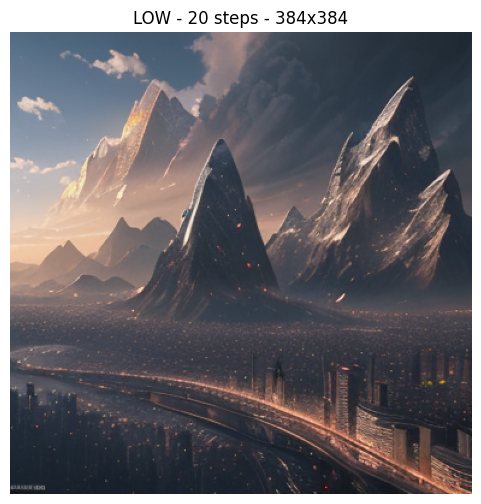


Testing profile: BALANCED

LITEGEN AI - ADAPTIVE GENERATION
Requested profile: BALANCED
Selected profile: BALANCED

Attempt: 1
Profile: BALANCED
Resolution: 512 x 512
Inference steps: 20


  0%|          | 0/20 [00:00<?, ?it/s]


GENERATION SUCCESSFUL!
{
    "requested_profile": "BALANCED",
    "selected_profile": "BALANCED",
    "precision": "FP16",
    "scheduler": "DEISMultistepScheduler",
    "steps": 20,
    "height": 512,
    "width": 512,
    "guidance_scale": 7.5,
    "seed": 12345,
    "latency_seconds": 3.1842203189999054,
    "peak_allocated_mb": 3257.84033203125,
    "peak_reserved_mb": 3830.0,
    "fallback_occurred": false,
    "image_path": "/content/LiteGen_Member4/outputs/generated_images/adaptive_balanced_12345.png",
    "status": "SUCCESS"
}


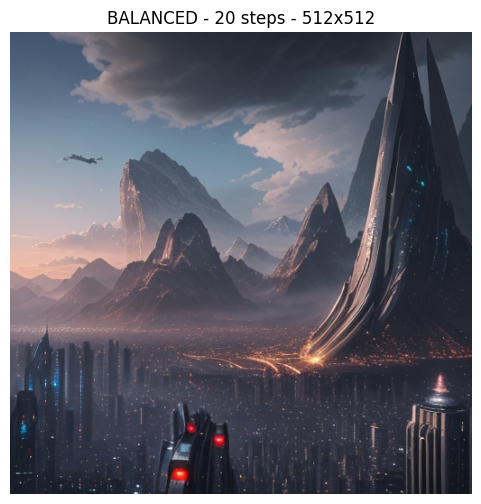


Testing profile: QUALITY

LITEGEN AI - ADAPTIVE GENERATION
Requested profile: QUALITY
Selected profile: QUALITY

Attempt: 1
Profile: QUALITY
Resolution: 512 x 512
Inference steps: 30


  0%|          | 0/30 [00:00<?, ?it/s]


GENERATION SUCCESSFUL!
{
    "requested_profile": "QUALITY",
    "selected_profile": "QUALITY",
    "precision": "FP16",
    "scheduler": "DEISMultistepScheduler",
    "steps": 30,
    "height": 512,
    "width": 512,
    "guidance_scale": 7.5,
    "seed": 12345,
    "latency_seconds": 4.721673127000031,
    "peak_allocated_mb": 3257.84033203125,
    "peak_reserved_mb": 3830.0,
    "fallback_occurred": false,
    "image_path": "/content/LiteGen_Member4/outputs/generated_images/adaptive_quality_12345.png",
    "status": "SUCCESS"
}


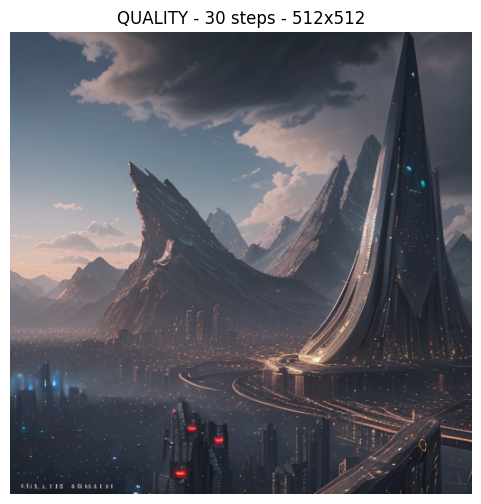


ALL ADAPTIVE PROFILE TESTS COMPLETED!
requested_profile selected_profile  steps  height  width  latency_seconds  peak_allocated_mb  status
              LOW              LOW     20     384    384         2.140478        2991.078125 SUCCESS
         BALANCED         BALANCED     20     512    512         3.184220        3257.840332 SUCCESS
          QUALITY          QUALITY     30     512    512         4.721673        3257.840332 SUCCESS

Results saved: /content/LiteGen_Member4/adaptive_generation_results.csv


In [67]:

# ============================================================
# STEP 22.2: TEST ALL THREE ADAPTIVE PROFILES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

adaptive_demo_results = []

for profile in ["LOW", "BALANCED", "QUALITY"]:

    print("\nTesting profile:", profile)

    image, log = adaptive_generate(
        prompt=PROMPT,
        requested_profile=profile,
        seed=12345
    )

    adaptive_demo_results.append(log)

    # Display generated image
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(
        f'{log["selected_profile"]} - '
        f'{log["steps"]} steps - '
        f'{log["height"]}x{log["width"]}'
    )
    plt.axis("off")
    plt.show()

# Create results DataFrame
adaptive_df = pd.DataFrame(adaptive_demo_results)

# Save generation results
adaptive_results_path = (
    BASE_DIR / "adaptive_generation_results.csv"
)

adaptive_df.to_csv(
    adaptive_results_path,
    index=False
)

print("\n" + "=" * 60)
print("ALL ADAPTIVE PROFILE TESTS COMPLETED!")
print("=" * 60)

print(
    adaptive_df[[
        "requested_profile",
        "selected_profile",
        "steps",
        "height",
        "width",
        "latency_seconds",
        "peak_allocated_mb",
        "status"
    ]].to_string(index=False)
)

print("\nResults saved:", adaptive_results_path)


In [68]:

# ============================================================
# STEP 23.1: SAVE CONTROLLER CONFIGURATION
# ============================================================

import json
import torch

controller_metadata = {

    "module": "LiteGen AI Adaptive Resource Manager",

    "member": 4,

    "controller_type": "Rule-based Resource-Aware Controller",

    "model": MODEL_ID,

    "device": torch.cuda.get_device_name(0),

    "precision": "FP16",

    "profiles": PROFILE_CONFIGS,

    "fallback_policy": {

        "profile_order": [
            "QUALITY",
            "BALANCED",
            "LOW"
        ],

        "automatic_fallback": True,

        "out_of_memory_retry": True,

        "retry_profile": "LOW",

        "memory_safety_margin": 0.10
    }
}

config_path = (
    BASE_DIR / "adaptive_controller_config.json"
)

with open(config_path, "w") as file:

    json.dump(
        controller_metadata,
        file,
        indent=4
    )

print("=" * 55)
print("CONTROLLER CONFIGURATION EXPORTED!")
print("=" * 55)

print("Saved at:", config_path)

print("\nCONFIGURATION:")
print(json.dumps(controller_metadata, indent=4))


CONTROLLER CONFIGURATION EXPORTED!
Saved at: /content/LiteGen_Member4/adaptive_controller_config.json

CONFIGURATION:
{
    "module": "LiteGen AI Adaptive Resource Manager",
    "member": 4,
    "controller_type": "Rule-based Resource-Aware Controller",
    "model": "Lykon/dreamshaper-8",
    "device": "Tesla T4",
    "precision": "FP16",
    "profiles": {
        "LOW": {
            "height": 384,
            "width": 384,
            "steps": 20,
            "guidance_scale": 7.5,
            "precision": "FP16",
            "scheduler": "DEISMultistepScheduler",
            "measured_peak_mb": 2990.95,
            "source_experiment": "E4_FP16_384x384"
        },
        "BALANCED": {
            "height": 512,
            "width": 512,
            "steps": 20,
            "guidance_scale": 7.5,
            "precision": "FP16",
            "scheduler": "DEISMultistepScheduler",
            "measured_peak_mb": 3257.71,
            "source_experiment": "E3_FP16_20_STEPS"
        },
 

In [69]:

# ============================================================
# STEP 23.2: SAVE ADAPTIVE EXPERIMENT SUMMARY
# ============================================================

import pandas as pd

summary_columns = [
    "requested_profile",
    "selected_profile",
    "precision",
    "scheduler",
    "steps",
    "height",
    "width",
    "latency_seconds",
    "peak_allocated_mb",
    "peak_reserved_mb",
    "fallback_occurred",
    "status"
]

adaptive_summary = adaptive_df[
    summary_columns
].copy()

summary_path = (
    BASE_DIR / "member4_adaptive_summary.csv"
)

adaptive_summary.to_csv(
    summary_path,
    index=False
)

print("=" * 55)
print("ADAPTIVE SUMMARY SAVED!")
print("=" * 55)

print(adaptive_summary.to_string(index=False))

print("\nFile:", summary_path)


ADAPTIVE SUMMARY SAVED!
requested_profile selected_profile precision              scheduler  steps  height  width  latency_seconds  peak_allocated_mb  peak_reserved_mb  fallback_occurred  status
              LOW              LOW      FP16 DEISMultistepScheduler     20     384    384         2.140478        2991.078125            3336.0              False SUCCESS
         BALANCED         BALANCED      FP16 DEISMultistepScheduler     20     512    512         3.184220        3257.840332            3830.0              False SUCCESS
          QUALITY          QUALITY      FP16 DEISMultistepScheduler     30     512    512         4.721673        3257.840332            3830.0              False SUCCESS

File: /content/LiteGen_Member4/member4_adaptive_summary.csv


In [70]:

# ============================================================
# STEP 24: VERIFY MEMBER 4 FILES
# ============================================================

required_files = [
    "member4_metrics.csv",
    "member4_clip_results.csv",
    "model_metadata.json",
    "controller_test_results.csv",
    "adaptive_generation_results.csv",
    "adaptive_controller_config.json",
    "member4_adaptive_summary.csv"
]

print("=" * 60)
print("LITEGEN AI - MEMBER 4 DELIVERABLE VERIFICATION")
print("=" * 60)

for filename in required_files:

    filepath = BASE_DIR / filename

    status = "FOUND" if filepath.exists() else "MISSING"

    print(filename, ":", status)

print("\nGenerated images:")

for image_path in sorted(IMAGE_DIR.glob("adaptive_*.png")):

    print(image_path.name)

print("\nVerification completed!")


LITEGEN AI - MEMBER 4 DELIVERABLE VERIFICATION
member4_metrics.csv : FOUND
member4_clip_results.csv : FOUND
model_metadata.json : FOUND
controller_test_results.csv : FOUND
adaptive_generation_results.csv : FOUND
adaptive_controller_config.json : FOUND
member4_adaptive_summary.csv : FOUND

Generated images:
adaptive_balanced_12345.png
adaptive_low_12345.png
adaptive_quality_12345.png

Verification completed!


In [71]:

# ============================================================
# LITEGEN AI
# STEP 24.1: CLASSICAL COMPUTER VISION SETUP
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter
from pathlib import Path
import pandas as pd
import json

# Create CV output directory
CV_DIR = BASE_DIR / "classical_cv"

CV_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 55)
print("CLASSICAL COMPUTER VISION MODULE")
print("=" * 55)

print("OpenCV version:", cv2.__version__)
print("Pillow version:", Image.__version__)
print("Output directory:", CV_DIR)

print("\nAll CV libraries loaded successfully!")


CLASSICAL COMPUTER VISION MODULE
OpenCV version: 4.14.0
Pillow version: 11.3.0
Output directory: /content/LiteGen_Member4/classical_cv

All CV libraries loaded successfully!


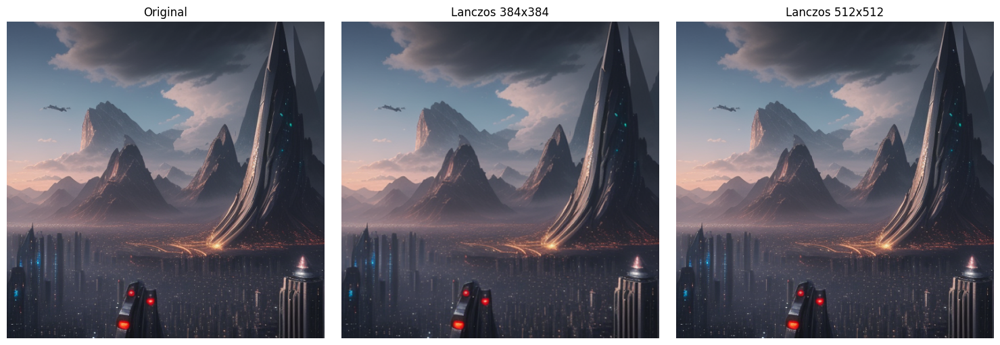

Lanczos resizing completed!


In [72]:

# ============================================================
# STEP 24.2: LANCZOS IMAGE RESIZING
# ============================================================

def lanczos_resize(image, width=512, height=512):

    if not isinstance(image, Image.Image):
        image = Image.fromarray(
            np.asarray(image).astype(np.uint8)
        )

    resized = image.resize(
        (width, height),
        Image.Resampling.LANCZOS
    )

    return resized


# Test using combined optimized image
source_image = combined_image.convert("RGB")

resized_384 = lanczos_resize(
    source_image, 384, 384
)

resized_512 = lanczos_resize(
    source_image, 512, 512
)

resized_384.save(CV_DIR / "lanczos_384.png")
resized_512.save(CV_DIR / "lanczos_512.png")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(source_image)
axes[0].set_title("Original")

axes[1].imshow(resized_384)
axes[1].set_title("Lanczos 384x384")

axes[2].imshow(resized_512)
axes[2].set_title("Lanczos 512x512")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Lanczos resizing completed!")


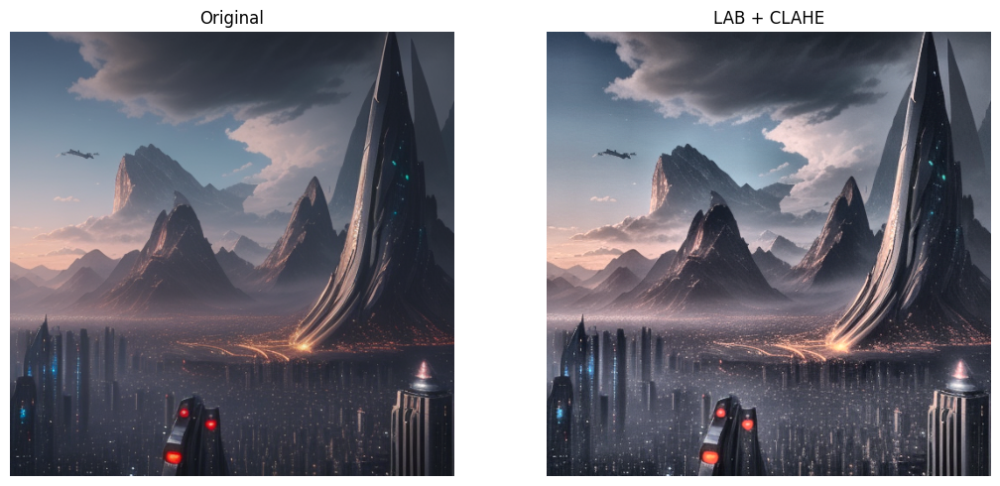

LAB + CLAHE enhancement completed!


In [73]:

# ============================================================
# STEP 24.3: LAB COLOUR SPACE + CLAHE
# ============================================================

def apply_lab_clahe(
    image,
    clip_limit=2.0,
    tile_grid_size=(8, 8)
):

    rgb = np.array(image.convert("RGB"))

    # Convert RGB to LAB
    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    # Split channels
    l_channel, a_channel, b_channel = cv2.split(lab)

    # Apply CLAHE to lightness channel
    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    enhanced_l = clahe.apply(l_channel)

    # Merge channels
    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    # Convert back to RGB
    enhanced_rgb = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(enhanced_rgb)


clahe_image = apply_lab_clahe(source_image)

clahe_image.save(
    CV_DIR / "clahe_enhanced.png"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(source_image)
axes[0].set_title("Original")

axes[1].imshow(clahe_image)
axes[1].set_title("LAB + CLAHE")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("LAB + CLAHE enhancement completed!")


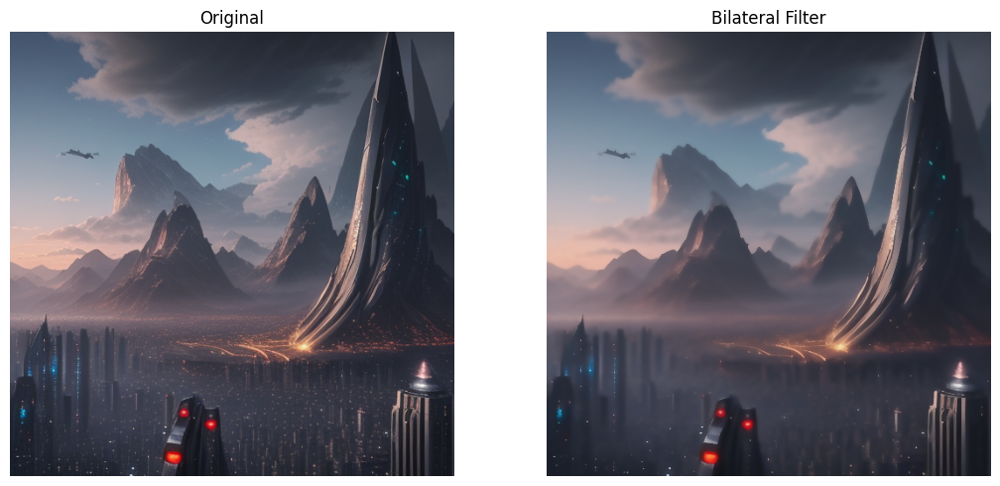

Bilateral filtering completed!


In [74]:

# ============================================================
# STEP 24.4: BILATERAL FILTERING
# ============================================================

def apply_bilateral_filter(
    image,
    diameter=9,
    sigma_color=75,
    sigma_space=75
):

    rgb = np.array(image.convert("RGB"))

    filtered = cv2.bilateralFilter(
        rgb,
        diameter,
        sigma_color,
        sigma_space
    )

    return Image.fromarray(filtered)


bilateral_image = apply_bilateral_filter(
    source_image
)

bilateral_image.save(
    CV_DIR / "bilateral_filtered.png"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(source_image)
axes[0].set_title("Original")

axes[1].imshow(bilateral_image)
axes[1].set_title("Bilateral Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Bilateral filtering completed!")


In [75]:

# ============================================================
# STEP 24.5: BLUR DETECTION
# ============================================================

def detect_blur(image, threshold=100):

    rgb = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2GRAY
    )

    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_64F
    )

    variance = float(laplacian.var())

    is_blurry = variance < threshold

    return {
        "laplacian_variance": variance,
        "threshold": threshold,
        "is_blurry": is_blurry,
        "status": "BLURRY" if is_blurry else "SHARP"
    }


blur_result = detect_blur(source_image)

print("=" * 50)
print("BLUR DETECTION RESULTS")
print("=" * 50)

print("Laplacian variance:",
      round(blur_result["laplacian_variance"], 2))

print("Threshold:",
      blur_result["threshold"])

print("Status:",
      blur_result["status"])

print("Is blurry:",
      blur_result["is_blurry"])


BLUR DETECTION RESULTS
Laplacian variance: 471.18
Threshold: 100
Status: SHARP
Is blurry: False


CONDITIONAL SHARPENING RESULTS
Original sharpness: 471.18
Action: SKIPPED - IMAGE ALREADY SHARP


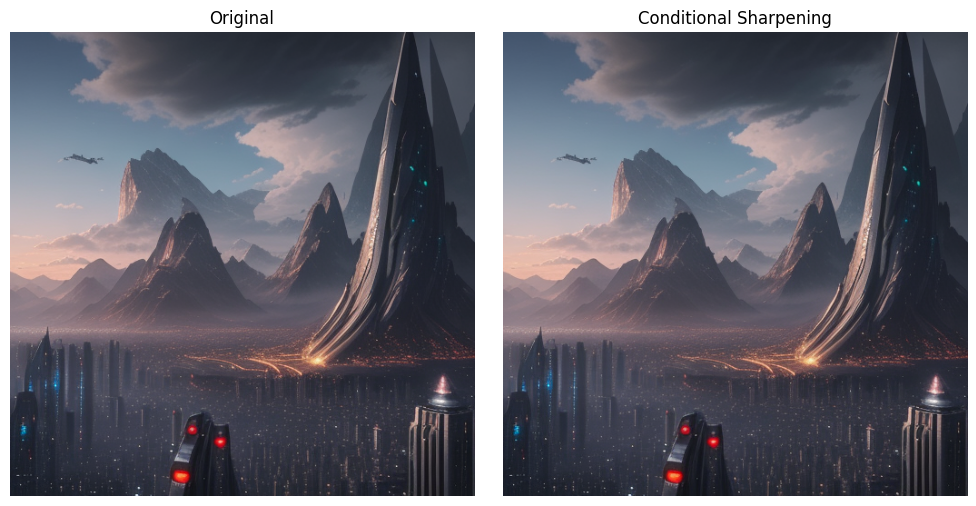

In [76]:

# ============================================================
# STEP 24.6: CONDITIONAL IMAGE SHARPENING
# ============================================================

def conditional_sharpen(
    image,
    threshold=100,
    amount=1.5,
    radius=1.2
):

    blur_info = detect_blur(
        image,
        threshold=threshold
    )

    if blur_info["is_blurry"]:

        # Unsharp masking
        original = image.convert("RGB")

        blurred = original.filter(
            ImageFilter.GaussianBlur(radius=radius)
        )

        sharpened = Image.blend(
            blurred,
            original,
            1.0 + amount
        )

        # Clip to valid RGB values
        sharpened = sharpened.convert("RGB")

        action = "SHARPENED"

    else:

        sharpened = image.copy()
        action = "SKIPPED - IMAGE ALREADY SHARP"

    return sharpened, {
        **blur_info,
        "sharpening_action": action
    }


sharpened_image, sharpening_info = conditional_sharpen(
    source_image
)

sharpened_image.save(
    CV_DIR / "conditionally_sharpened.png"
)

print("=" * 55)
print("CONDITIONAL SHARPENING RESULTS")
print("=" * 55)

print("Original sharpness:",
      round(sharpening_info["laplacian_variance"], 2))

print("Action:",
      sharpening_info["sharpening_action"])

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(source_image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened_image)
plt.title("Conditional Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()


In [77]:

# ============================================================
# STEP 24.7: CLIP QUALITY GUARD
# ============================================================

def clip_quality_guard(
    original_image,
    enhanced_image,
    prompt,
    tolerance=0.01
):

    # Calculate original similarity
    original_score = calculate_clip_similarity(
        prompt,
        original_image
    )

    # Calculate enhanced similarity
    enhanced_score = calculate_clip_similarity(
        prompt,
        enhanced_image
    )

    score_difference = (
        enhanced_score - original_score
    )

    accepted = (
        enhanced_score >= original_score - tolerance
    )

    if accepted:
        selected_image = enhanced_image
        decision = "ENHANCEMENT ACCEPTED"

    else:
        selected_image = original_image.copy()
        decision = "ENHANCEMENT REJECTED"

    return selected_image, {
        "original_clip_similarity": original_score,
        "enhanced_clip_similarity": enhanced_score,
        "similarity_difference": score_difference,
        "tolerance": tolerance,
        "accepted": accepted,
        "decision": decision
    }


print("CLIP quality guard initialized!")


CLIP quality guard initialized!


In [78]:

# ============================================================
# STEP 24.8: COMPLETE CLASSICAL CV PIPELINE
# ============================================================

def classical_cv_pipeline(
    image,
    prompt,
    target_size=512
):

    print("=" * 60)
    print("LITEGEN AI - CLASSICAL CV PIPELINE")
    print("=" * 60)

    # 1. Lanczos resizing
    resized = lanczos_resize(
        image,
        target_size,
        target_size
    )

    # 2. LAB + CLAHE
    clahe_result = apply_lab_clahe(resized)

    # 3. Bilateral filtering
    bilateral_result = apply_bilateral_filter(
        clahe_result
    )

    # 4. Blur detection and conditional sharpening
    sharpened_result, blur_info = conditional_sharpen(
        bilateral_result
    )

    # 5. CLIP quality guard
    final_image, clip_info = clip_quality_guard(
        resized,
        sharpened_result,
        prompt
    )

    # Save final output
    output_path = CV_DIR / "final_enhanced_image.png"

    final_image.save(output_path)

    # Save processing metadata
    metadata = {
        "resize_method": "Lanczos",
        "target_size": target_size,
        "contrast_enhancement": "LAB + CLAHE",
        "noise_reduction": "Bilateral Filter",
        "blur_detection": blur_info,
        "clip_quality_guard": clip_info,
        "output_path": str(output_path)
    }

    with open(CV_DIR / "cv_metadata.json", "w") as f:
        json.dump(metadata, f, indent=4)

    print("\nPIPELINE COMPLETED!")
    print("Blur status:", blur_info["status"])
    print("Sharpening:", blur_info["sharpening_action"])
    print("CLIP decision:", clip_info["decision"])
    print("Output:", output_path)

    return final_image, metadata


print("Complete Classical CV pipeline ready!")


Complete Classical CV pipeline ready!


LITEGEN AI - CLASSICAL CV PIPELINE

PIPELINE COMPLETED!
Blur status: SHARP
Sharpening: SKIPPED - IMAGE ALREADY SHARP
CLIP decision: ENHANCEMENT ACCEPTED
Output: /content/LiteGen_Member4/classical_cv/final_enhanced_image.png


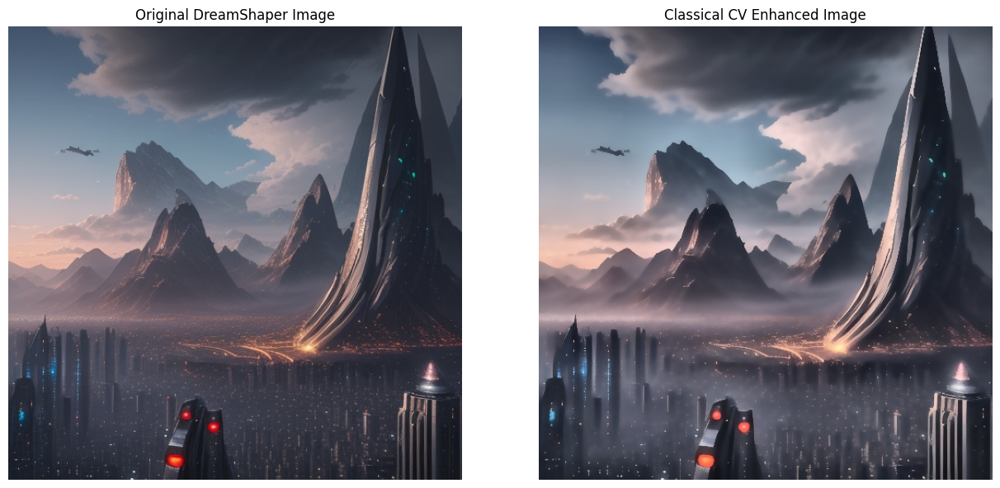


FINAL CLIP EVALUATION
Original: 0.3272
Enhanced: 0.3335
Decision: ENHANCEMENT ACCEPTED


In [79]:

# ============================================================
# STEP 24.9: RUN COMPLETE CLASSICAL CV PIPELINE
# ============================================================

final_cv_image, cv_metadata = classical_cv_pipeline(
    image=combined_image,
    prompt=PROMPT,
    target_size=512
)

# Display original and enhanced images
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(combined_image)
axes[0].set_title("Original DreamShaper Image")
axes[0].axis("off")

axes[1].imshow(final_cv_image)
axes[1].set_title("Classical CV Enhanced Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("\nFINAL CLIP EVALUATION")

print(
    "Original:",
    round(
        cv_metadata["clip_quality_guard"]["original_clip_similarity"],
        4
    )
)

print(
    "Enhanced:",
    round(
        cv_metadata["clip_quality_guard"]["enhanced_clip_similarity"],
        4
    )
)

print(
    "Decision:",
    cv_metadata["clip_quality_guard"]["decision"]
)


In [80]:

# ============================================================
# STEP 24.10: SAVE CLASSICAL CV RESULTS
# ============================================================

cv_record = {
    "module": "Classical Computer Vision",
    "input_image": "dreamshaper_combined_optimized.png",
    "resize_method": "Lanczos",
    "target_resolution": "512x512",
    "contrast_method": "LAB_CLAHE",
    "filter_method": "Bilateral",
    "blur_variance": cv_metadata["blur_detection"]["laplacian_variance"],
    "sharpening_action": cv_metadata["blur_detection"]["sharpening_action"],
    "original_clip_similarity": cv_metadata["clip_quality_guard"]["original_clip_similarity"],
    "enhanced_clip_similarity": cv_metadata["clip_quality_guard"]["enhanced_clip_similarity"],
    "clip_decision": cv_metadata["clip_quality_guard"]["decision"],
    "output_image": "final_enhanced_image.png"
}

cv_results_path = CV_DIR / "classical_cv_results.csv"

pd.DataFrame([cv_record]).to_csv(
    cv_results_path,
    index=False
)

print("CLASSICAL CV RESULTS SAVED!")
print("Location:", cv_results_path)

print(pd.DataFrame([cv_record]).to_string(index=False))


CLASSICAL CV RESULTS SAVED!
Location: /content/LiteGen_Member4/classical_cv/classical_cv_results.csv
                   module                        input_image resize_method target_resolution contrast_method filter_method  blur_variance             sharpening_action  original_clip_similarity  enhanced_clip_similarity        clip_decision             output_image
Classical Computer Vision dreamshaper_combined_optimized.png       Lanczos           512x512       LAB_CLAHE     Bilateral     731.567724 SKIPPED - IMAGE ALREADY SHARP                  0.327244                  0.333529 ENHANCEMENT ACCEPTED final_enhanced_image.png


In [81]:

# ============================================================
# STEP 25.1: FINAL MEMBER 4 FILE VERIFICATION
# ============================================================

required_files = [
    "member4_metrics.csv",
    "member4_clip_results.csv",
    "model_metadata.json",
    "controller_test_results.csv",
    "adaptive_generation_results.csv",
    "adaptive_controller_config.json",
    "member4_adaptive_summary.csv"
]

print("=" * 60)
print("LITEGEN AI - MEMBER 4 FINAL VERIFICATION")
print("=" * 60)

for filename in required_files:

    path = BASE_DIR / filename

    print(
        filename,
        ":", "FOUND" if path.exists() else "MISSING"
    )

print("\nCLASSICAL CV FILES")

for path in sorted(CV_DIR.iterdir()):

    if path.is_file():
        print(path.name)

print("\nADAPTIVE GENERATED IMAGES")

for path in sorted(IMAGE_DIR.glob("adaptive_*.png")):

    print(path.name)

print("\nVERIFICATION FINISHED!")


LITEGEN AI - MEMBER 4 FINAL VERIFICATION
member4_metrics.csv : FOUND
member4_clip_results.csv : FOUND
model_metadata.json : FOUND
controller_test_results.csv : FOUND
adaptive_generation_results.csv : FOUND
adaptive_controller_config.json : FOUND
member4_adaptive_summary.csv : FOUND

CLASSICAL CV FILES
bilateral_filtered.png
clahe_enhanced.png
classical_cv_results.csv
conditionally_sharpened.png
cv_metadata.json
final_enhanced_image.png
lanczos_384.png
lanczos_512.png

ADAPTIVE GENERATED IMAGES
adaptive_balanced_12345.png
adaptive_low_12345.png
adaptive_quality_12345.png

VERIFICATION FINISHED!


In [82]:

# ============================================================
# STEP 25.2: CREATE MEMBER 4 FINAL ZIP
# ============================================================

import shutil
from pathlib import Path

zip_path = Path("/content/LiteGen_Member4_Final")

# Include all Member 4 outputs
shutil.make_archive(
    str(zip_path),
    "zip",
    root_dir=BASE_DIR
)

final_zip = Path("/content/LiteGen_Member4_Final.zip")

print("=" * 55)
print("MEMBER 4 PACKAGE CREATED!")
print("=" * 55)

print("ZIP location:", final_zip)
print("ZIP size:", round(final_zip.stat().st_size / 1024**2, 2), "MB")

print("\nReady for download!")


MEMBER 4 PACKAGE CREATED!
ZIP location: /content/LiteGen_Member4_Final.zip
ZIP size: 6.58 MB

Ready for download!


In [83]:

# ============================================================
# STEP 26: ENVIRONMENT METADATA
# ============================================================

import sys
import json
import platform
import torch
import diffusers
import transformers
import cv2
import PIL
import pandas as pd
from datetime import datetime

environment_metadata = {
    "project": "LiteGen AI",
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "diffusers_version": diffusers.__version__,
    "transformers_version": transformers.__version__,
    "opencv_version": cv2.__version__,
    "pillow_version": PIL.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    ),
    "gpu_vram_mb": (
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**2,
            2
        )
        if torch.cuda.is_available() else None
    ),
    "clip_model": "openai/clip-vit-base-patch32",
    "recorded_at": datetime.now().isoformat()
}

environment_path = BASE_DIR / "member4_environment.json"

with open(environment_path, "w") as f:
    json.dump(environment_metadata, f, indent=4)

print("ENVIRONMENT METADATA SAVED!")
print(json.dumps(environment_metadata, indent=4))
print("\nFile:", environment_path)


ENVIRONMENT METADATA SAVED!
{
    "project": "LiteGen AI",
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pytorch_version": "2.14.1+cu130",
    "diffusers_version": "0.42.1",
    "transformers_version": "5.22.1",
    "opencv_version": "4.14.0",
    "pillow_version": "11.3.0",
    "cuda_available": true,
    "gpu_name": "Tesla T4",
    "gpu_vram_mb": 14912.69,
    "clip_model": "openai/clip-vit-base-patch32",
    "recorded_at": "2026-11-07T04:47:02.562460"
}

File: /content/LiteGen_Member4/member4_environment.json


In [84]:

# ============================================================
# STEP 27: SAVE BEST VALID CONFIGURATION
# ============================================================

import pandas as pd
import json

metrics_path = BASE_DIR / "member4_metrics.csv"

results_df = pd.read_csv(metrics_path)

# Select the measured 384x384 FP16 experiment
candidate = results_df[
    results_df["run_id"] == "E4_FP16_384x384"
]

if candidate.empty:
    raise ValueError("384x384 experiment not found in metrics CSV.")

best_row = candidate.iloc[0]

best_configuration = {
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "selection_status": "PROVISIONAL_BEST_CANDIDATE",
    "precision": str(best_row["precision"]),
    "scheduler": str(best_row["scheduler"]),
    "height": int(best_row["height"]),
    "width": int(best_row["width"]),
    "steps": int(best_row["steps"]),
    "guidance_scale": float(best_row["guidance_scale"]),
    "seed": int(best_row["seed"]),
    "measured_latency_seconds": float(best_row["latency_seconds"]),
    "peak_allocated_mb": float(best_row["peak_allocated_mb"]),
    "peak_reserved_mb": float(best_row["peak_reserved_mb"]),
    "clip_similarity": float(best_row["clip_similarity"]),
    "selection_basis": (
        "Best observed CLIP score among the 11 evaluated "
        "experiments, with lower measured memory than 512x512. "
        "Single-run measurements; further validation required."
    )
}

best_config_path = BASE_DIR / "member4_best_config.json"

with open(best_config_path, "w") as f:
    json.dump(best_configuration, f, indent=4)

print("BEST CONFIGURATION RECORD SAVED!")
print(json.dumps(best_configuration, indent=4))
print("\nFile:", best_config_path)


BEST CONFIGURATION RECORD SAVED!
{
    "member": 4,
    "model_id": "Lykon/dreamshaper-8",
    "selection_status": "PROVISIONAL_BEST_CANDIDATE",
    "precision": "FP16",
    "scheduler": "DEISMultistepScheduler",
    "height": 384,
    "width": 384,
    "steps": 20,
    "guidance_scale": 7.5,
    "seed": 12345,
    "measured_latency_seconds": 2.1140959099998327,
    "peak_allocated_mb": 2990.9521484375,
    "peak_reserved_mb": 3336.0,
    "clip_similarity": 0.3346811830997467,
    "selection_basis": "Best observed CLIP score among the 11 evaluated experiments, with lower measured memory than 512x512. Single-run measurements; further validation required."
}

File: /content/LiteGen_Member4/member4_best_config.json


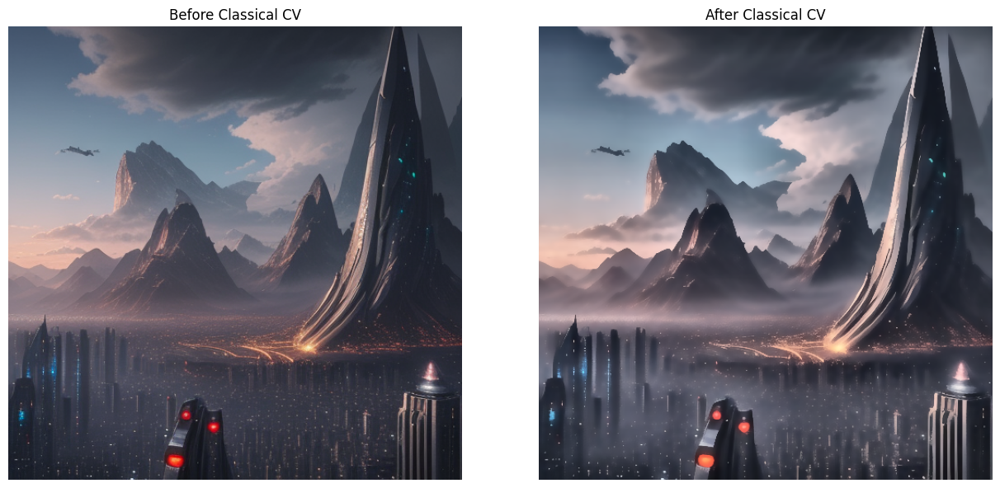

CV COMPARISON SAVED!

  stage  width  height  sharpness_laplacian_variance  brightness_mean  brightness_std  edge_density
BEFORE    512     512                    471.175813        85.918262       43.399049      0.039169
 AFTER    512     512                    731.567724        96.411446       47.586302      0.046535

Grid: /content/LiteGen_Member4/classical_cv/cv_before_after_grid.png
Metrics: /content/LiteGen_Member4/classical_cv/cv_before_after_metrics.csv


In [85]:

# ============================================================
# STEP 28: SAVE CV BEFORE/AFTER COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import cv2
import pandas as pd

def cv_quality_metrics(image):

    array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        array,
        cv2.COLOR_RGB2GRAY
    )

    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_64F
    )

    edges = cv2.Canny(gray, 100, 200)

    return {
        "width": image.width,
        "height": image.height,
        "sharpness_laplacian_variance": float(laplacian.var()),
        "brightness_mean": float(gray.mean()),
        "brightness_std": float(gray.std()),
        "edge_density": float(np.mean(edges > 0))
    }


before_metrics = cv_quality_metrics(combined_image)
after_metrics = cv_quality_metrics(final_cv_image)

# Save comparison grid
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(combined_image)
axes[0].set_title("Before Classical CV")
axes[0].axis("off")

axes[1].imshow(final_cv_image)
axes[1].set_title("After Classical CV")
axes[1].axis("off")

plt.tight_layout()

grid_path = CV_DIR / "cv_before_after_grid.png"

plt.savefig(
    grid_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save metrics
comparison_metrics = pd.DataFrame([
    {"stage": "BEFORE", **before_metrics},
    {"stage": "AFTER", **after_metrics}
])

comparison_path = CV_DIR / "cv_before_after_metrics.csv"

comparison_metrics.to_csv(
    comparison_path,
    index=False
)

print("CV COMPARISON SAVED!")
print("\n", comparison_metrics.to_string(index=False))

print("\nGrid:", grid_path)
print("Metrics:", comparison_path)


In [86]:

# ============================================================
# STEP 29: FINAL MEMBER 4 PACKAGE
# ============================================================

import shutil
from pathlib import Path

zip_base = Path("/content/LiteGen_Member4_Final")

final_zip = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=BASE_DIR
)

print("=" * 55)
print("FINAL MEMBER 4 PACKAGE CREATED")
print("=" * 55)

print("ZIP:", final_zip)

print(
    "Size:",
    round(Path(final_zip).stat().st_size / 1024**2, 2),
    "MB"
)

print("\nPACKAGE READY!")


FINAL MEMBER 4 PACKAGE CREATED
ZIP: /content/LiteGen_Member4_Final.zip
Size: 8.61 MB

PACKAGE READY!
